# Project P03: Financial 10-K Analyst. Grounded Answers with Exact Calculations

**Team:** Vyom Nikhra, <member A>, <member B>, <member C>

| Member | Contribution (sections, code, experiments) |
|---|---|
| Vyom Nikhra | System design and all code: retrieval (5a), tools and sandbox (5b), agent graph (5b), evaluation harness (6), demo (8) |
| <member A> | Hand-verified the derived calculation set and hand-labelled 100 question-type tags (3); data and design slides |
| <member B> | Hand-labelled answers for judge validation (6); results and ablation slides |
| <member C> | Categorised the failure cases (7); wrote limitations and ethics (9); error-analysis slides |

## 1. Problem Statement

- **Problem (our own words):** Analysts ask questions about annual reports (10-K filings) that mix
  *lookup* ("what was services revenue?") with *arithmetic* ("what share of revenue came from
  services?"). Small language models misread figures from long passages and make token-level
  arithmetic slips. We build a single ReAct agent that retrieves the right filing passage, extracts the
  numbers, and computes any result with a sandboxed Python tool, so numbers are never guessed.
- **Research question:** Does a ≤4B model that delegates retrieval (hybrid RAG with a ticker filter) and
  arithmetic (a sandboxed Python tool) through a ReAct loop beat plain RAG and RAG + chain-of-thought on
  *calculation* questions without losing accuracy on *lookup* questions, and at what cost?
- **What success looks like (targets fixed before any test results):**
  - retrieval Recall@5 ≥ 0.90 with the ticker filter;
  - on calculation questions, numeric accuracy at least 15 points above RAG + CoT;
  - on lookup questions, judge accuracy within 3 points of plain RAG;
  - the calculator is called on ≥ 90% of calculation questions.

## 2. Setup

The notebook runs top to bottom on a laptop with [Ollama](https://ollama.com) or on Colab (T4). On Colab, the
cell after the config installs Ollama, starts the server and pulls both models. On a laptop, install Ollama and
run `ollama pull qwen3:4b-instruct` and `ollama pull phi4-mini` once (see `README.md`).

The following environment variables override the defaults without editing the notebook:
- `AGENT_MODEL` and `JUDGE_MODEL`: the models to use.
- `OLLAMA_HOST`: the Ollama address.

Long LLM jobs write one JSON line per item to `artifacts/`. A crashed run resumes where it stopped, and a
re-run reuses earlier results.

In [1]:
%pip install -q datasets==5.1.0 sentence-transformers==6.2.0 transformers==5.21.0 faiss-cpu==1.15.1 rank-bm25==0.2.2 scikit-learn==1.9.1 langgraph==1.2.18 langchain-core==1.7.0 langchain-ollama==1.1.0 pydantic==2.14.1 pandas==3.1.0 numpy==2.4.6 matplotlib==3.11.2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import json
import math
import os
import random
import re
import subprocess
import sys
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Flags (environment variables override the defaults, so a full run can be started without editing the notebook)
QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1"                # True: evaluate a small fixed sample live
USE_CACHED_PREDS = os.environ.get("USE_CACHED_PREDS", "1") == "1"  # True: full set from artifacts/preds, no live runs
GENERATE_DERIVED = os.environ.get("GENERATE_DERIVED", "0") == "1"   # True: let the LLM generate missing derived items
IN_COLAB = "google.colab" in sys.modules

CONFIG = {
    "dataset": "virattt/financial-qa-10K",
    "dataset_revision": "30e48b49ef40389cce6488b0bddef7d6f00f4c7a",   # HF commit, pinned for reproducibility
    "agent_model": os.environ.get("AGENT_MODEL", "qwen3:4b-instruct"),
    "judge_model": os.environ.get("JUDGE_MODEL", "phi4-mini"),
    "ollama_host": os.environ.get("OLLAMA_HOST", "http://localhost:11434"),
    "embedder": "BAAI/bge-small-en-v1.5",
    "embedder_baseline": "sentence-transformers/all-MiniLM-L6-v2",
    "reranker": "cross-encoder/ms-marco-MiniLM-L-6-v2",
    "top_k": 5,
    "rrf_k": 60,
    "rerank_pool": 20,
    "max_steps": 6,
    "agent_num_ctx": 8192,     # set explicitly: Ollama silently truncates prompts longer than the context window
    "n_test_lookup_per_type": 100,
    "n_dev_lookup_per_type": 15,
    "n_dev_derived": 20,
    "n_quick_per_type": 10,
    "n_derived_candidates": 250,
}
if "://" not in CONFIG["ollama_host"]:
    CONFIG["ollama_host"] = "http://" + CONFIG["ollama_host"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ART = Path("artifacts")
for sub in ("cache", "labels", "derived", "preds", "judge"):
    (ART / sub).mkdir(parents=True, exist_ok=True)

print(f"python {sys.version.split()[0]} | torch {torch.__version__} | device {DEVICE} | colab {IN_COLAB}")
print(json.dumps(CONFIG, indent=1))

python 3.11.9 | torch 2.14.1+cu126 | device cuda | colab False
{
 "dataset": "virattt/financial-qa-10K",
 "dataset_revision": "30e48b49ef40389cce6488b0bddef7d6f00f4c7a",
 "agent_model": "qwen3:4b-instruct",
 "judge_model": "phi4-mini",
 "ollama_host": "http://localhost:11434",
 "embedder": "BAAI/bge-small-en-v1.5",
 "embedder_baseline": "sentence-transformers/all-MiniLM-L6-v2",
 "reranker": "cross-encoder/ms-marco-MiniLM-L-6-v2",
 "top_k": 5,
 "rrf_k": 60,
 "rerank_pool": 20,
 "max_steps": 6,
 "agent_num_ctx": 8192,
 "n_test_lookup_per_type": 100,
 "n_dev_lookup_per_type": 15,
 "n_dev_derived": 20,
 "n_quick_per_type": 10,
 "n_derived_candidates": 250
}


In [3]:
def ollama_version():
    try:
        return json.load(urllib.request.urlopen(f"{CONFIG['ollama_host']}/api/version", timeout=3))["version"]
    except OSError:
        return None


if IN_COLAB:
    subprocess.run("curl -fsSL https://ollama.com/install.sh | sh", shell=True, check=True)
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    for _ in range(60):
        if ollama_version():
            break
        time.sleep(1)
    for m in (CONFIG["agent_model"], CONFIG["judge_model"]):
        subprocess.run(["ollama", "pull", m], check=True)

version = ollama_version()
if version is None:
    raise RuntimeError(f"Ollama is not reachable at {CONFIG['ollama_host']}: start the Ollama app or `ollama serve`.")
pulled = {m["name"] for m in json.load(urllib.request.urlopen(f"{CONFIG['ollama_host']}/api/tags"))["models"]}
missing = [m for m in (CONFIG["agent_model"], CONFIG["judge_model"]) if m not in pulled and f"{m}:latest" not in pulled]
if missing:
    raise RuntimeError(f"Pull these Ollama models first: {missing}")
print(f"Ollama {version} at {CONFIG['ollama_host']}; models ready: {CONFIG['agent_model']}, {CONFIG['judge_model']}")

Ollama 0.40.13 at http://localhost:11434; models ready: qwen3:4b-instruct, phi4-mini


In [4]:
from langchain_ollama import ChatOllama


def get_llm(model, temperature=0.0, num_predict=512, seed=SEED, **kw):
    return ChatOllama(model=model, base_url=CONFIG["ollama_host"], temperature=temperature,
                      num_predict=num_predict, seed=seed, **kw)


class JsonlStore:
    """Append-only JSONL file keyed by row["id"], so long LLM jobs resume after a crash and re-runs reuse results."""

    def __init__(self, path):
        self.path = Path(path)
        self.rows = {}
        if self.path.exists():
            for line in self.path.read_text(encoding="utf-8").splitlines():
                row = json.loads(line)
                self.rows[row["id"]] = row

    def __contains__(self, key):
        return key in self.rows

    def __getitem__(self, key):
        return self.rows[key]

    def __len__(self):
        return len(self.rows)

    def add(self, row):
        with self.path.open("a", encoding="utf-8") as f:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")
        self.rows[row["id"]] = row

## 3. Data

`virattt/financial-qa-10K`: 7,000 question/answer pairs, each with the 10-K passage it was written from
(`context`) and the company `ticker`. The knowledge base is the set of **unique passages**. The questions are
held out for evaluation and never indexed.

In [5]:
from datasets import load_dataset

ds = load_dataset(CONFIG["dataset"], revision=CONFIG["dataset_revision"])["train"]
print(ds)
raw = ds.to_pandas()
raw.insert(0, "qid", [f"q{i}" for i in range(len(raw))])   # stable ids: row position in the pinned revision
display(raw.head(3))

D:\kumarran-folder\projects\p03_10k_analyst\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset({
    features: ['question', 'answer', 'context', 'ticker', 'filing'],
    num_rows: 7000
})


,qid,question,answer,context,ticker,filing
0,q0,What area did NVIDIA initially focus on before...,NVIDIA initially focused on PC graphics.,"Since our original focus on PC graphics, we ha...",NVDA,2023_10K
1,q1,What are some of the recent applications of GP...,Recent applications of GPU-powered deep learni...,Some of the most recent applications of GPU-po...,NVDA,2023_10K
2,q2,What significant invention did NVIDIA create i...,NVIDIA invented the GPU in 1999.,Our invention of the GPU in 1999 defined moder...,NVDA,2023_10K


### 3.1 Cleaning and exploration

dropped 3 rows with an empty field and 7 exact duplicate rows -> 6990 rows
tickers: 69; rows per ticker: {199: 1, 100: 62, 99: 3, 98: 3}
filing values: ['2023_10K'] (a single value, so useless as a filter)
duplicate questions within a ticker: 42


,count,mean,std,min,50%,95%,99%,max
question,6990.0,14.7,4.2,3.0,14.0,22.0,26.0,36.0
answer,6990.0,19.1,15.2,1.0,18.0,47.0,64.0,124.0
context,6990.0,32.9,24.8,1.0,27.0,74.0,120.0,787.0


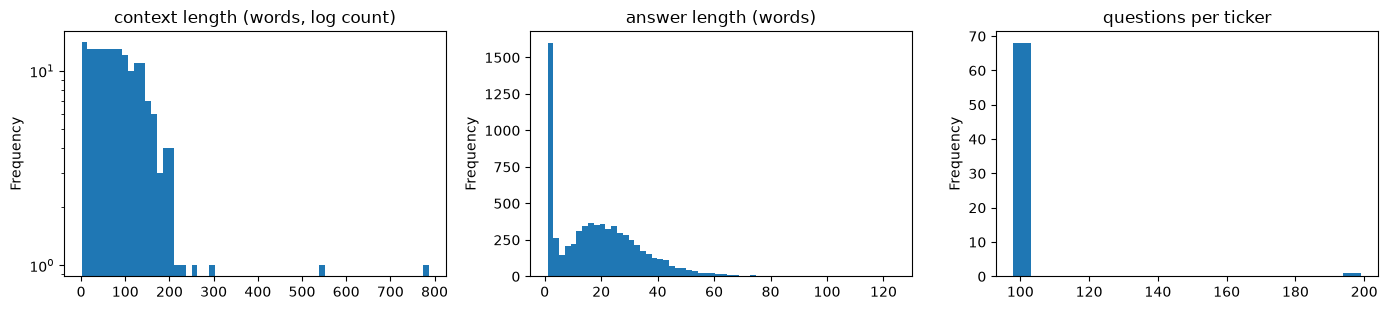

In [6]:
df = raw.copy()
for c in ["question", "answer", "context", "ticker"]:
    df[c] = df[c].str.strip()
empty = (df[["question", "answer", "context"]] == "").any(axis=1)
dupes = df.duplicated(["question", "answer", "context", "ticker"]) & ~empty
df = df[~empty & ~dupes].reset_index(drop=True)
print(f"dropped {int(empty.sum())} rows with an empty field and {int(dupes.sum())} exact duplicate rows -> {len(df)} rows")
print(f"tickers: {df.ticker.nunique()}; rows per ticker: {dict(Counter(df.ticker.value_counts()))}")
print(f"filing values: {sorted(df.filing.unique())} (a single value, so useless as a filter)")
print(f"duplicate questions within a ticker: {int(df.duplicated(['question', 'ticker']).sum())}")

words = df[["question", "answer", "context"]].apply(lambda s: s.str.split().str.len())
display(words.describe(percentiles=[.5, .95, .99]).round(1).T)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
words.context.drop_duplicates().plot.hist(bins=60, ax=axes[0], log=True, title="context length (words, log count)")
words.answer.plot.hist(bins=60, ax=axes[1], title="answer length (words)")
df.ticker.value_counts().plot.hist(bins=20, ax=axes[2], title="questions per ticker")
plt.tight_layout()
plt.show()

### 3.2 Knowledge base: deduplicated passages

Each unique (ticker, normalised passage) is one document, with no further chunking.
- **Why no chunking (design choice D1):** passages are already short (median about 27 words), and splitting
  them would break the one-to-one link between a question and its gold passage that Recall@k relies on.
- **Near-duplicates:** some passages repeat inside others. When one same-ticker passage contains another, both
  count as relevant for that question, so retrieving either one is a hit.

In [7]:
from transformers import AutoTokenizer


def norm_text(s):
    return re.sub(r"\s+", " ", s.lower()).strip()


df["ctx_norm"] = df.context.map(norm_text)
docs = df[["ticker", "context", "ctx_norm"]].drop_duplicates(["ticker", "ctx_norm"]).reset_index(drop=True)
docs.insert(0, "doc_id", [f"D{i:05d}" for i in range(len(docs))])
doc_key = {(t, n): d for d, t, n in docs[["doc_id", "ticker", "ctx_norm"]].itertuples(index=False)}
df["gold_doc"] = [doc_key[(t, n)] for t, n in zip(df.ticker, df.ctx_norm)]

related = {d: {d} for d in docs.doc_id}
for _, g in docs.groupby("ticker"):
    items = list(zip(g.doc_id, g.ctx_norm))
    for da, a in items:
        for db, b in items:
            if da != db and a in b:
                related[da].add(db)
                related[db].add(da)
df["relevant_docs"] = df.gold_doc.map(lambda d: sorted(related[d]))

emb_tokenizer = AutoTokenizer.from_pretrained(CONFIG["embedder"])
n_tokens = docs.context.map(lambda t: len(emb_tokenizer(t, verbose=False)["input_ids"]) if len(t) > 1500 else 0)  # 512 tokens > 1500 chars
print(f"documents: {len(docs)} unique passages across {docs.ticker.nunique()} tickers")
print(f"documents with a same-ticker near-duplicate: {sum(len(v) > 1 for v in related.values())}")
print(f"questions whose relevant set has more than one passage: {int((df.relevant_docs.str.len() > 1).sum())}")
print(f"passages longer than the embedder's 512-token window (tail truncated): {int((n_tokens > 512).sum())}")

documents: 6756 unique passages across 69 tickers
documents with a same-ticker near-duplicate: 104
questions whose relevant set has more than one passage: 136
passages longer than the embedder's 512-token window (tail truncated): 2


### 3.3 Number parsing

Figures in 10-K text come in many forms: `$1,234.5 million`, `(6)%` for negatives, `-34.7%`, and tables in
thousands. The parser below normalises them. It drops dates, bare years, section references like `10(b)` and
list markers like `1)`, and it records how many decimals were shown so rounded answers can be matched. The
question tagger (3.4) and the numeric-match metric (6) both use it.

In [8]:
MONTHS = (r"(?:Jan(?:uary)?|Feb(?:ruary)?|Mar(?:ch)?|Apr(?:il)?|May|June?|July?|Aug(?:ust)?|"
          r"Sep(?:t(?:ember)?)?|Oct(?:ober)?|Nov(?:ember)?|Dec(?:ember)?)")
DATE_RE = re.compile(rf"\b{MONTHS}\.?\s+\d{{1,2}}(?:st|nd|rd|th)?,?\s+\d{{4}}|\b{MONTHS}\.?\s+\d{{4}}"
                     rf"|\b{MONTHS}\.?\s+\d{{1,2}}(?:st|nd|rd|th)?\b", re.I)
NUM_RE = re.compile(
    r"(?<![A-Za-z0-9_.])(\()?(-|−)?\$?\s?((?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?)(\))?"
    r"(?!\s*\([A-Za-z]\))(?![A-Za-z0-9])\s*(%|percent\b)?\s*(thousand|million|billion|trillion|bn)?\b", re.I)
SCALE = {"thousand": 1e3, "million": 1e6, "billion": 1e9, "bn": 1e9, "trillion": 1e12}


def extract_numbers(text):
    """Numbers in `text` as dicts: value (signed, scale words applied), shown (as written), dec, pct, scaled."""
    out = []
    for m in NUM_RE.finditer(DATE_RE.sub(" ", text)):
        lp, minus, digits, rp, pct, scale = m.groups()
        if rp and not lp:
            continue                                           # list marker such as "1)"
        shown = float(digits.replace(",", ""))
        bare = not pct and not scale and "$" not in m.group(0) and "," not in digits and "." not in digits
        if bare and 1900 <= shown <= 2099:
            continue                                           # a year
        if minus or (lp and rp):
            shown = -shown
        out.append({"value": shown * SCALE.get((scale or "").lower(), 1.0), "shown": shown, "pct": bool(pct),
                    "scaled": bool(scale), "scale_word": (scale or "").lower(), "dollar": "$" in m.group(0),
                    "dec": len(digits.split(".")[1]) if "." in digits else 0})
    return out


def same_up_to_presentation(a, b, rel=0.005):
    """|a| and |b| agree within `rel`, allowing a 1000^k change of scale (tables in thousands vs text in millions)."""
    a, b = abs(a), abs(b)
    if a == 0 or b == 0:
        return a == b
    return any(math.isclose(a, b * 1000.0 ** k, rel_tol=rel) for k in range(-3, 4))


def matches_target(target, x, rel=0.01):
    """Does computed value x reproduce parsed number `target`, within `rel` or after rounding to target's precision?"""
    t = abs(target["value"])
    if t == 0:
        return abs(x) < 1e-9
    unit = t / abs(target["shown"])                            # scale word multiplier of the target
    for k in range(-3, 4):
        y = abs(x) * 1000.0 ** k
        if math.isclose(t, y, rel_tol=rel) or round(y / unit, target["dec"]) == round(abs(target["shown"]), target["dec"]):
            return True
    return False


def values(text):
    return [n["value"] for n in extract_numbers(text)]


assert values("Revenue was $1,234.5 million in 2023, up 12% from (45) in 2022.") == [1234.5e6, 12.0, -45.0]
assert values("Sections 10(b) and 20(a); on August 29, 2021 and in fiscal 2023") == []
assert values("The three goals are: 1) growth, 2) margin") == []
assert values("decreased by 34.7%") == [34.7] and values("-6%") == [-6.0] and values("$5.2 billion") == [5.2e9]
assert values("Q4 2023 EPS of $1.50") == [1.5]
assert same_up_to_presentation(74_203, 74.2e6) and not same_up_to_presentation(5.2e6, 5.2e9 * 1.1)
assert matches_target(extract_numbers("about 31 percent")[0], 4 / 13 * 100)
print("number parser tests passed")

number parser tests passed


### 3.4 Question types: lookup or calculation

The brief asks us to tag each question as lookup or calculation. We use **deterministic rules** and check
every calculation tag arithmetically:

| Type | Rule |
|---|---|
| `text_lookup` | the gold answer contains no (non-date) number |
| `numeric_lookup` | every number in the answer appears in the passage or question (up to scale, sign, rounding) |
| `calculation` | each *new* number in the answer is reproduced by **one** operation on two passage numbers: a−b, a+b, a/b, a/b×100, or (a−b)/b×100 |
| `unexplained` | a new number that no single operation reproduces; usually a gold answer with facts not in the passage. Excluded from the test sets. |

Requiring the arithmetic to reproduce the gold number also checks the gold answer. Coincidental matches are
possible, so a teammate verifies every real `calculation` item, and blind-labels a stratified sample of 100
rows to measure agreement (3.5).

In [9]:
def reproducible(target, pool):
    vals = [p["value"] for p in pool]
    for i, a in enumerate(vals):
        for j, b in enumerate(vals):
            if i == j:
                continue
            cands = [a - b, a + b] + ([a / b, a / b * 100, (a - b) / abs(b) * 100] if b else [])
            if any(matches_target(target, c) for c in cands):
                return True
    return False


def question_type(question, answer, context):
    ans = extract_numbers(answer)
    if not ans:
        return "text_lookup"
    pool = extract_numbers(context) + extract_numbers(question)
    new = [n for n in ans if not any(same_up_to_presentation(n["value"], p["value"]) for p in pool)]
    if not new:
        return "numeric_lookup"
    ctx_nums = extract_numbers(context)
    return "calculation" if all(reproducible(n, ctx_nums) for n in new) else "unexplained"


df["qtype"] = [question_type(q, a, c) for q, a, c in zip(df.question, df.answer, df.context)]
display(df.qtype.value_counts().rename("questions").to_frame())
for kind in ("calculation", "unexplained"):
    print(f"\n--- {kind}: 3 examples ---")
    for r in df[df.qtype == kind].sample(3, random_state=SEED).itertuples():
        print(f"Q: {r.question}\nA: {r.answer}\nC: {r.context[:240]}\n")

,questions
qtype,
text_lookup,3470
numeric_lookup,3422
unexplained,50
calculation,48



--- calculation: 3 examples ---
Q: How did the goodwill value change over the period in the data provided?
A: The goodwill value remained constant at $69,021 before decreasing by $1 to $69,022.
C: Throughout the period, the goodwill value maintained a constant value of $69,021 before a slight decrease to $69,022.

Q: What is the expected total repurchase amount of the company's common stock in 2023 and 2024?
A: $2.5 billion
C: In June 2023, the company entered into an ASR agreement to repurchase $500 million of its common stock with a completion date no later than August 2023, and in 2024, the company expects to repurchase $2.0 billion of its common stock.

Q: What was the increase in income tax benefit for All Other from 2022 to 2023?
A: $2.4 billion
C: The income tax benefit was $8.4 billion in 2023 compared to a benefit of $6.0 billion in 2022. The income tax benefit in All Other resulted from both periods having income tax benefit adjustments to allocate the FTE treatment of certa

### 3.5 Human checks of the labels

The notebook exports three files to `artifacts/labels/`. A teammate fills them in and saves each one under the
"completed" name shown below. Exports are written only once, so a re-run never overwrites labelling work.

| Export | Task | Completed file |
|---|---|---|
| `qtype_sample_to_label.csv` | 100 rows, stratified, **without the rule's tag** (blind). Fill `human_label` with `text_lookup`, `numeric_lookup`, `calculation` or `unexplained`. | `qtype_human_labels.csv` |
| `real_calc_to_verify.csv` | Every real `calculation` row. Set `verified` to `yes` if the gold answer is correct and needs arithmetic on the passage. | `real_calc_verified.csv` |
| `derived_calc_to_verify.csv` | Every derived question from 3.6. Set `verified` to `yes` if the question is sensible and the gold answer is right. | `derived_calc_verified.csv` |

Until the completed files exist, every item counts as `pending` and the notebook says so.

In [10]:
LABELS = ART / "labels"


def export_once(frame, name):
    path = LABELS / name
    if path.exists():
        print(f"kept existing {path} (not overwritten)")
    else:
        frame.to_csv(path, index=False)
        print(f"wrote {path} ({len(frame)} rows)")


def read_verified(name, key):
    """Ids marked verified == yes in a completed label file, or None if the file isn't there yet."""
    path = LABELS / name
    if not path.exists():
        return None
    done = pd.read_csv(path)
    return set(done.loc[done.verified.astype(str).str.strip().str.lower() == "yes", key])


blind = pd.concat([df[df.qtype == "text_lookup"].sample(40, random_state=SEED),
                   df[df.qtype == "numeric_lookup"].sample(35, random_state=SEED),
                   df[df.qtype == "calculation"].sample(15, random_state=SEED),
                   df[df.qtype == "unexplained"].sample(10, random_state=SEED)]).sample(frac=1, random_state=SEED)
export_once(blind[["qid", "ticker", "question", "answer", "context"]].assign(human_label=""), "qtype_sample_to_label.csv")
export_once(df[df.qtype == "calculation"][["qid", "ticker", "question", "answer", "context"]].assign(verified="", note=""),
            "real_calc_to_verify.csv")

human_path = LABELS / "qtype_human_labels.csv"
if human_path.exists():
    from sklearn.metrics import cohen_kappa_score
    h = pd.read_csv(human_path).merge(df[["qid", "qtype"]], on="qid")
    h = h[h.human_label.notna() & (h.human_label.astype(str).str.strip() != "")]
    print(f"rule vs human on {len(h)} rows: agreement {np.mean(h.human_label == h.qtype):.1%}, "
          f"Cohen's kappa {cohen_kappa_score(h.human_label, h.qtype):.2f}")
    display(pd.crosstab(h.human_label, h.qtype, rownames=["human"], colnames=["rule"]))
else:
    print(f"PENDING: {human_path} not provided yet, so rule-vs-human agreement is not computed")

real_calc_ok = read_verified("real_calc_verified.csv", "qid")
print("real calculation items:", int((df.qtype == "calculation").sum()),
      "| human-verified:" , "pending" if real_calc_ok is None else len(real_calc_ok))

kept existing artifacts\labels\qtype_sample_to_label.csv (not overwritten)
kept existing artifacts\labels\real_calc_to_verify.csv (not overwritten)
PENDING: artifacts\labels\qtype_human_labels.csv not provided yet, so rule-vs-human agreement is not computed
real calculation items: 48 | human-verified: pending


### 3.6 Derived calculation questions

Only 48 real questions need arithmetic, which is too few to compare systems on calculation. We therefore
derive more from the same knowledge base:
1. **Pick passages.** Short passages (under 600 characters) with at least two money amounts (a `$` sign or a
   million/billion word). These are not the source passage of any real calculation or unexplained question.
2. **Write a question.** `phi4-mini` writes one question needing one arithmetic step, and returns the
   operation and the two operands **copied verbatim** in a schema-constrained JSON output (the structured
   generation pattern from the Module 2 lab). It is not the agent model, so the agent never answers its own
   questions.
3. **Reject bad items.** Code rejects an item if an operand is not in the passage verbatim, does not parse to
   exactly one number, or mixes percentages with amounts. It also rejects items whose result is already
   stated in the passage or question, since that would be a lookup.
4. **Compute the gold answer in Python,** never by the LLM.

Every derived item is labelled `derived_calculation` and reported separately from real questions.

In [11]:
from typing import Literal

from pydantic import BaseModel, Field


OP_SPEC = {   # definition shown to the generator, example phrasing, and words the question must contain
    "difference": ("operand_a minus operand_b, reported as a positive amount (operand_a is the later period or larger item)",
                   "By how much did X increase from 2022 to 2023?",
                   ("difference", "how much", "increase", "decrease", "more", "less", "change", "higher", "lower", "grow")),
    "percent_change": ("(operand_a - operand_b) / operand_b * 100, where operand_a is the later value and operand_b the earlier",
                       "By what percentage did X change from 2022 to 2023?", ("percent", "%")),
    "share_of_total": ("operand_a / operand_b * 100, where operand_a is a part and operand_b is the total it belongs to",
                       "What percentage of total X did Y represent?", ("percent", "%", "share", "proportion", "portion")),
    "ratio": ("operand_a / operand_b", "What is the ratio of X to Y?", ("ratio", "times", "multiple")),
    "sum": ("operand_a plus operand_b", "What were X and Y combined?", ("total", "combined", "sum", "together", "aggregate")),
}
OP_CYCLE = list(OP_SPEC)
OPS = {"difference": lambda a, b: abs(a - b), "sum": lambda a, b: a + b, "ratio": lambda a, b: a / b,
       "share_of_total": lambda a, b: a / b * 100, "percent_change": lambda a, b: (a - b) / abs(b) * 100}


def derived_schema(op):
    """Schema with `operation` fixed to one value: the generator cannot drift to an easier operation."""

    class DerivedQuestion(BaseModel):
        question: str = Field(description="One question that needs exactly this arithmetic step on two numbers "
                                          "from the passage. Do not state the answer.")
        operation: Literal[op]
        operand_a: str = Field(description="The first number copied exactly as written in the passage, "
                                           "with its $ sign or unit word")
        operand_b: str = Field(description="The second number copied exactly as written in the passage")

    return DerivedQuestion


DERIVE_PROMPT = """You write evaluation questions for a financial analyst assistant.

Passage from the company's 10-K filing:
\"\"\"{context}\"\"\"

Write ONE question whose answer requires exactly one arithmetic step on two financial amounts that appear in
the passage. Use only money amounts or counts of business units (stores, employees, customers). Never use page
numbers, dates, addresses, phone numbers, or note/item numbers.
The arithmetic step must be: {operation} = {definition}
Phrase the question like: "{example}"
The answer must NOT already be written in the passage. Refer to the company as "the company".
Copy operand_a and operand_b exactly as they are written in the passage."""


def fmt_amount(r, a, b):
    """Gold text for an amount, in the operands' style: keep their scale word unless the result is below one unit."""
    unit = max(SCALE.get(a["scale_word"], 1.0), SCALE.get(b["scale_word"], 1.0))
    while unit > 1 and abs(r) < unit:
        unit /= 1000
    word = {1e3: "thousand", 1e6: "million", 1e9: "billion", 1e12: "trillion"}.get(unit, "")
    dec = max([n["dec"] for n in (a, b) if SCALE.get(n["scale_word"], 1.0) == unit] or [1])
    return ("-" if r < 0 else "") + ("$" if a["dollar"] else "") + f"{abs(r) / unit:,.{dec}f}" + (f" {word}" if word else "")


def check_derived(context, dq):
    """Validate one generated item; return (gold value, gold answer text) or raise ValueError(reason)."""
    if not any(w in dq.question.lower() for w in OP_SPEC[dq.operation][2]):
        raise ValueError(f"question wording does not ask for a {dq.operation}")
    for o in (dq.operand_a, dq.operand_b):
        if norm_text(o) not in norm_text(context):
            raise ValueError("operand not verbatim in passage")
    na, nb = extract_numbers(dq.operand_a), extract_numbers(dq.operand_b)
    if len(na) != 1 or len(nb) != 1:
        raise ValueError("operand does not parse to exactly one number")
    a, b = na[0], nb[0]
    if a["value"] == b["value"]:
        raise ValueError("identical operands")
    if dq.operation in ("difference", "sum") and (a["pct"], a["dollar"]) != (b["pct"], b["dollar"]):
        raise ValueError("operands are different kinds (percent, dollar or other amount)")
    if dq.operation in ("percent_change", "ratio", "share_of_total") and (a["pct"] or b["pct"] or b["value"] == 0):
        raise ValueError("ratio-type operation needs two non-zero amounts")
    r = OPS[dq.operation](a["value"], b["value"])
    if dq.operation == "share_of_total" and not 0 < r < 100:
        raise ValueError("share of total outside 0-100%")
    if any(same_up_to_presentation(r, n["value"]) for n in extract_numbers(context) + extract_numbers(dq.question)):
        raise ValueError("result already stated in passage or question")
    if dq.operation in ("percent_change", "share_of_total"):
        return r, f"{r:.1f}%"
    if dq.operation == "ratio":
        return r, f"{r:.2f}"
    if a["pct"]:
        return r, f"{r:.1f} percentage points"
    return r, fmt_amount(r, a, b)


def money_count(text):
    return sum(1 for n in extract_numbers(text) if (n["dollar"] or n["scaled"]) and not n["pct"])


def generate_derived(context, op):
    gen = get_llm(CONFIG["judge_model"], num_predict=300).with_structured_output(derived_schema(op), method="json_schema")
    spec = OP_SPEC[op]
    return gen.invoke(DERIVE_PROMPT.format(context=context, operation=op, definition=spec[0], example=spec[1]))

In [12]:
excluded = set(df.loc[df.qtype.isin(["calculation", "unexplained"]), "gold_doc"])
pool = docs[(docs.context.str.len() < 600) & (docs.context.map(money_count) >= 2) & ~docs.doc_id.isin(excluded)]
candidates = pool.sample(min(CONFIG["n_derived_candidates"], len(pool)), random_state=SEED)
print(f"passages eligible for derived questions: {len(pool)}; sampled: {len(candidates)}")

derived_store = JsonlStore(ART / "derived" / "derived_calc_raw_v3.jsonl")
todo = [r for r in candidates.itertuples() if r.doc_id not in derived_store]
if todo and not GENERATE_DERIVED:
    raise RuntimeError(f"{len(todo)} derived candidates have no saved result in {derived_store.path}; "
                       "set GENERATE_DERIVED = True (about 3 s per item) to generate them")
if todo:
    t0 = time.time()
    op_for = {d: OP_CYCLE[i % len(OP_CYCLE)] for i, d in enumerate(candidates.doc_id)}   # balance the operations
    for i, r in enumerate(todo, 1):
        row = {"id": r.doc_id, "doc_id": r.doc_id, "ticker": r.ticker, "context": r.context,
               "requested_operation": op_for[r.doc_id]}
        try:
            dq = generate_derived(r.context, op_for[r.doc_id])
            row.update(dq.model_dump())
            row["gold_value"], row["gold_answer"] = check_derived(r.context, dq)
            row["status"] = "ok"
        except ValueError as e:              # failed validation or unparseable LLM output: recorded, not retried
            row["status"] = f"rejected: {str(e).splitlines()[0][:80]}"
        derived_store.add(row)
        if i % 25 == 0:
            print(f"  {i}/{len(todo)} generated ({time.time() - t0:.0f}s)")

raw_derived = pd.DataFrame([derived_store[d] for d in candidates.doc_id])
display(raw_derived.status.value_counts().rename("items").to_frame())
derived = raw_derived[raw_derived.status == "ok"].reset_index(drop=True)
derived.insert(0, "qid", [f"x{d[1:]}_{hashlib.sha1(q.encode()).hexdigest()[:6]}"     # stable if regenerated
                          for d, q in zip(derived.doc_id, derived.question)])
display(derived.operation.value_counts().rename("derived questions").to_frame())
export_once(derived[["qid", "ticker", "question", "operation", "operand_a", "operand_b", "gold_answer", "context"]]
            .assign(verified="", note=""), "derived_calc_to_verify.csv")
derived_ok = read_verified("derived_calc_verified.csv", "qid")    # applied in 3.7, after the split assignment
print(f"derived calculation questions passing the automatic checks: {len(derived)}; human-verified: "
      f"{'pending' if derived_ok is None else len(derived_ok & set(derived.qid))}")
display(derived[["question", "operation", "operand_a", "operand_b", "gold_answer"]].head(5))

passages eligible for derived questions: 774; sampled: 250

,items
status,
ok,169
rejected: operand not verbatim in passage,48
rejected: result already stated in passage or question,14
rejected: identical operands,6
rejected: operand does not parse to exactly one number,5
"rejected: operands are different kinds (percent, dollar or other amount)",5
rejected: share of total outside 0-100%,3


,derived questions
operation,
ratio,45
sum,40
percent_change,31
share_of_total,27
difference,26


kept existing artifacts\labels\derived_calc_to_verify.csv (not overwritten)
derived calculation questions passing the automatic checks: 169; human-verified: pending


,question,operation,operand_a,operand_b,gold_answer
0,What is the ratio of the increase in total deb...,ratio,$8.99 billion,$16.24 billion,0.55
1,By what percentage did cash contributions to t...,percent_change,$78.5 million,$27.6 million,184.4%
2,What is the ratio of cash returned to sharehol...,ratio,$2.4 billion,$2.3 billion,1.04
3,By how much did the amortization expense for a...,difference,$67 million,$18 million,$49 million
4,What percentage of total U.S. covered litigati...,share_of_total,"$1,441 million","$1,621 million",88.9%


### 3.7 Fixed dev / test subsets

All draws use `SEED`. The **dev** set is only for prompt iteration; every reported number comes from **test**.

| Split | Contents |
|---|---|
| test | 100 `text_lookup` + 100 `numeric_lookup` + **all** real `calculation` questions + all derived questions except 20 |
| dev | 15 `text_lookup` + 15 `numeric_lookup` + 20 derived questions. No real calculation question is used for dev, so all of them stay in test. |
| quick | 10 test questions per type. Used live when `QUICK_RUN = True`. |

Calculation items that a teammate marks as wrong (3.5, 3.6) are removed **after** this assignment. A rejected
item therefore never pulls another question from dev into test; the type just has fewer questions.

In [13]:
def real_rows(frame, kind):
    return pd.DataFrame({"qid": frame.qid, "source": "real", "ticker": frame.ticker, "question": frame.question,
                         "gold_answer": frame.answer, "qtype": kind, "gold_doc": frame.gold_doc,
                         "relevant_docs": frame.relevant_docs})


n_dev, n_test = CONFIG["n_dev_lookup_per_type"], CONFIG["n_test_lookup_per_type"]
parts = []
for kind in ("text_lookup", "numeric_lookup"):
    pick = df[df.qtype == kind].sample(n_dev + n_test, random_state=SEED)
    parts += [real_rows(pick.iloc[:n_dev], kind).assign(split="dev"),
              real_rows(pick.iloc[n_dev:], kind).assign(split="test")]
parts.append(real_rows(df[df.qtype == "calculation"], "calculation").assign(split="test"))
der = pd.DataFrame({"qid": derived.qid, "source": "derived", "ticker": derived.ticker, "question": derived.question,
                    "gold_answer": derived.gold_answer, "qtype": "derived_calculation", "gold_doc": derived.doc_id,
                    "relevant_docs": derived.doc_id.map(lambda d: sorted(related[d]))})
der_order = der.sample(frac=1, random_state=SEED)
parts += [der_order.iloc[:CONFIG["n_dev_derived"]].assign(split="dev"),
          der_order.iloc[CONFIG["n_dev_derived"]:].assign(split="test")]
questions = pd.concat(parts, ignore_index=True)

# Numbers the numeric-match metric (section 6) compares against: for real calculation questions, only the numbers
# the passage does not already state; for everything else, every number in the gold answer.
calc_gold = {r.qid: [n["value"] for n in extract_numbers(r.answer)
                     if not any(same_up_to_presentation(n["value"], p["value"]) for p in extract_numbers(r.context))]
             for r in df[df.qtype == "calculation"].itertuples()}
gold_value = dict(zip(derived.qid, derived.gold_value))
questions["gold_numbers"] = [calc_gold[q] if t == "calculation" else [gold_value[q]] if t == "derived_calculation"
                             else values(a) for q, t, a in zip(questions.qid, questions.qtype, questions.gold_answer)]

quick_ids = set()
for kind, g in questions[questions.split == "test"].groupby("qtype"):
    quick_ids |= set(g.sample(min(CONFIG["n_quick_per_type"], len(g)), random_state=SEED).qid)
questions["quick"] = questions.qid.isin(quick_ids)

# Items a teammate rejected are dropped only now, after dev/test/quick were assigned, so verification never moves a
# question between dev and test.
keep = pd.Series(True, index=questions.index)
for kind, ok in (("calculation", real_calc_ok), ("derived_calculation", derived_ok)):
    if ok is not None:
        keep &= (questions.qtype != kind) | questions.qid.isin(ok)
print(f"dropped {int((~keep).sum())} items that failed human verification")
questions = questions[keep].reset_index(drop=True)

(ART / "splits.json").write_text(json.dumps({s: sorted(g.qid) for s, g in questions.groupby("split")}, indent=1))
questions.to_json(ART / "questions.jsonl", orient="records", lines=True, force_ascii=False)
display(pd.crosstab(questions.qtype, questions.split, margins=True))
print(f"quick subset: {int(questions.quick.sum())} questions")

dropped 0 items that failed human verification


split,dev,test,All
qtype,,,
calculation,0,48,48
derived_calculation,20,149,169
numeric_lookup,15,100,115
text_lookup,15,100,115
All,50,397,447


quick subset: 40 questions


## 4. Baseline

### 4.1 Evaluation harness (shared with section 6)

**Which questions are run.**

| Flags | Questions | What happens |
|---|---|---|
| `QUICK_RUN = True` | the 40-question quick subset | missing predictions run live |
| `QUICK_RUN = False`, `USE_CACHED_PREDS = True` | the full test set | loaded from `artifacts/preds/` and re-scored here; missing predictions raise an error |
| `QUICK_RUN = False`, `USE_CACHED_PREDS = False` | the full test set | missing predictions run live (hours on a laptop GPU) |

Predictions and judge verdicts are stored per condition and per model, one JSON line per question, so a run
can stop and resume.

**Metrics**
- **Judge accuracy.** A verdict is correct only if all three checks pass, in this order:
  1. **Not a refusal.** "The filing does not contain…" is never correct, because every gold answer exists.
  2. **Number check (rules).** For numeric-lookup questions, at least one gold figure must appear in the answer.
     For calculation questions, every gold figure must appear.
  3. **LLM judge.** `phi4-mini`, from a different family than the agent, compares the meaning with a strict
     rubric.

  On real answers the LLM judge alone said YES to refusals and to wrong figures, such as "$138.0M" against a gold
  "$132.4M" (dev check, logbook 2026-10-28). That is why the rule checks run first. Section 6 validates the
  combined verdict against human labels.
- **Numeric accuracy** (calculation questions): every gold number must appear in the answer within 1%, either at
  its exact value or as rounded in the gold answer text (exact 0.963%, gold "1.0%", answer "1%"). Answers
  written ×100 or ÷100 count, as in Program-of-Thoughts' `finqa_equal`. The scale (thousand / million / billion)
  is checked only when both the answer and the gold state one: "$1,318 million" matches a gold "$1,318.0" taken
  from a table in millions. The sign is ignored, because answers phrase decreases in words.
- **Calculator use**, **citation accuracy** (the cited passage is a relevant one), and **cost** (seconds, LLM
  calls and tokens per question).

In [14]:
eval_q = questions[(questions.split == "test") & (questions.quick | (not QUICK_RUN))].reset_index(drop=True)
MODEL_TAG = re.sub(r"[^A-Za-z0-9]+", "-", CONFIG["agent_model"]).strip("-")
print(f"evaluation set: {'quick subset' if QUICK_RUN else 'full test set'}, {len(eval_q)} questions")
display(eval_q.qtype.value_counts().rename("questions").to_frame())


# Bump a version whenever that system's prompt or code changes. It is part of the cache file name, so predictions
# made by an older version are never reused.
BASELINE_VERSION, AGENT_VERSION = "v1", "v3"


def live_allowed(kind):
    if USE_CACHED_PREDS and not QUICK_RUN:
        raise RuntimeError(f"{kind} missing from the cache and USE_CACHED_PREDS = True. Run the full evaluation once "
                           "with USE_CACHED_PREDS = False (several hours on a laptop GPU) or set QUICK_RUN = True.")


def run_condition(name, answer_fn, version, qs=None):
    """Predictions for one condition: cached rows are reused, missing ones are computed by answer_fn(row)."""
    qs = eval_q if qs is None else qs
    store = JsonlStore(ART / "preds" / f"{name}__{MODEL_TAG}__{version}.jsonl")
    stale = [r.qid for r in qs.itertuples() if r.qid in store and store[r.qid]["question"] != r.question]
    if stale:
        raise RuntimeError(f"cached predictions in {store.path} were made for different question text: {stale[:5]}")
    missing = [r for r in qs.itertuples() if r.qid not in store]
    if missing:
        live_allowed(f"{len(missing)} predictions for {name!r} are")
        t0 = time.time()
        for i, r in enumerate(missing, 1):
            store.add({"id": r.qid, "condition": name, "question": r.question, **answer_fn(r)})
            if i % 20 == 0 or i == len(missing):
                print(f"  {name}: {i}/{len(missing)} ({time.time() - t0:.0f}s)")
    return pd.DataFrame([store[q] for q in qs.qid])


JUDGE_TEMPLATE = (
    "You grade answers to questions about company annual reports.\n"
    "Question: {q}\nGold answer: {gold}\nCandidate answer: {pred}\n\n"
    "Rules: the candidate is correct only if it states the same key fact as the gold answer. "
    "Every key number must match the gold number after converting units (million/billion, percent/fraction); "
    "rounding to the precision shown in the gold answer is fine. A different number, the opposite direction "
    "(increase vs decrease), different entities, or no answer means NO. Extra correct detail is fine.\n"
    "Reply with exactly one word: YES or NO.")
JUDGE_VERSION = "strict-v1"     # part of the cache file name: changing the prompt must not reuse old verdicts
judge_llm = get_llm(CONFIG["judge_model"], num_predict=5)
judge_store = JsonlStore(ART / "judge" / f"{CONFIG['judge_model'].replace(':', '-')}__{JUDGE_VERSION}.jsonl")
REFUSAL_RE = re.compile(
    r"\b(?:does not|doesn't|do not|did not|cannot|can't|unable to)\s+(?:\w+\s+){0,3}?"
    r"(?:contain|provide|include|mention|disclose|specify|report|find|answer)\b"
    r"|\bnot (?:available|provided|disclosed|mentioned|found|specified|included)\b"
    r"|\bno (?:information|data|figure|specific)\b|\bI'?m sorry\b|\bdon'?t have that information\b", re.I)


def judge_answer(question, gold, pred):
    raw = judge_llm.invoke(JUDGE_TEMPLATE.format(q=question, gold=gold, pred=pred)).content.strip()
    m = re.match(r"\W*(YES|NO)\b", raw.upper())
    return (m.group(1) == "YES") if m else None, raw[:40]


def judge_key(question, gold, answer):
    return hashlib.sha1(f"{question}\n{gold}\n{answer}".encode()).hexdigest()[:20]


def judge_condition(name, preds, qs=None):
    """LLM verdicts, cached by (question, gold, answer): any answer the judge has seen before is not re-judged."""
    qs = eval_q if qs is None else qs
    answers = dict(zip(preds.id, preds.answer))
    keys = {r.qid: judge_key(r.question, r.gold_answer, answers[r.qid]) for r in qs.itertuples()}
    missing = [r for r in qs.itertuples() if keys[r.qid] not in judge_store]
    if missing:
        live_allowed(f"{len(missing)} judge verdicts for {name!r} are")
        for r in missing:
            ok, raw = judge_answer(r.question, r.gold_answer, answers[r.qid])
            judge_store.add({"id": keys[r.qid], "qid": r.qid, "answer": answers[r.qid], "correct": ok, "raw": raw})
    return {q: judge_store[k]["correct"] for q, k in keys.items()}


def numeric_correct(answer, gold_numbers, gold_answer):
    """Every gold number appears in `answer` within 1%, either at its exact value or as rounded in the gold answer
    (exact 0.963, gold text "1.0%", answer "1%"). A gold answer with no scale word (e.g. "$1,318.0" from a table in
    millions) does not fix the scale, so then the answer's scale is not checked either."""
    preds = extract_numbers(answer)
    gold_shown = extract_numbers(gold_answer)
    gold_unscaled = not any(n["scaled"] for n in gold_shown)

    def hit(g):
        g = abs(g)
        for p in preds:
            v = abs(p["value"])
            rescale = not p["scaled"] or gold_unscaled
            cands = [v, v * 100, v / 100] + ([v * 1000.0 ** k for k in (-3, -2, -1, 1, 2, 3)] if rescale else [])
            if any(math.isclose(c, g, rel_tol=0.01) for c in cands):
                return True
        return False

    def matched(g):
        rounded = [n["value"] for n in gold_shown if math.isclose(abs(n["value"]), abs(g), rel_tol=0.05)]
        return hit(g) or any(hit(r) for r in rounded)

    return all(matched(g) for g in gold_numbers) if gold_numbers else None


assert numeric_correct("It grew by $5,606 million.", [5.606e9], "$5.6 billion") and numeric_correct("about 30.8%", [31.0], "31%")
assert not numeric_correct("It grew by $5.6 billion and 12%.", [8.548e9], "$8.5 billion")
assert numeric_correct("Services were 0.125 of revenue", [12.5], "12.5%")
assert not numeric_correct("$5.2 billion", [5.2e6], "$5.2 million") and numeric_correct("$1,318 million", [1318.0], "$1,318.0")
assert numeric_correct("It rose 1%", [0.9626], "1.0%") and not numeric_correct("about $1 billion", [1.4e9], "$1.4 billion")

CALC_TYPES = ("calculation", "derived_calculation")
assert REFUSAL_RE.search("The 2023 annual report does not contain information about it")
assert REFUSAL_RE.search("I'm sorry, but there is no publicly available report") and not REFUSAL_RE.search("Revenue was $5 billion")


def rule_gate(qtype, answer, gold_numbers, gold_answer):
    """Checks that run before the LLM judge: (passed, reason it failed)."""
    if REFUSAL_RE.search(answer):
        return False, "refusal"
    if qtype in CALC_TYPES and not numeric_correct(answer, gold_numbers, gold_answer):
        return False, "number mismatch"
    if qtype == "numeric_lookup" and gold_numbers and not any(numeric_correct(answer, [g], gold_answer)
                                                              for g in gold_numbers):
        return False, "number mismatch"
    return True, None


def score(name, preds, qs=None):
    """Per-question metrics for one condition, merged with the question table."""
    qs = eval_q if qs is None else qs
    verdicts = judge_condition(name, preds, qs)
    p = qs.merge(preds.drop(columns="question").rename(columns={"id": "qid"}), on="qid")   # run_condition checked it
    p["condition"] = name
    gates = [rule_gate(t, a, g, ga) for t, a, g, ga in zip(p.qtype, p.answer, p.gold_numbers, p.gold_answer)]
    p["refusal"] = [why == "refusal" for _, why in gates]
    p["llm_judge_ok"] = p.qid.map(verdicts)
    p["judge_ok"] = [False if not gate_ok else llm for (gate_ok, _), llm in zip(gates, p.llm_judge_ok)]
    p["fail_reason"] = [why if not ok else ("LLM judge" if llm is False else None)
                        for (ok, why), llm in zip(gates, p.llm_judge_ok)]
    p["numeric_ok"] = [numeric_correct(a, g, ga) if t in CALC_TYPES else None
                       for a, g, ga, t in zip(p.answer, p.gold_numbers, p.gold_answer, p.qtype)]
    p["calc_called"] = [any(c["name"] == "run_python" for c in tc) for tc in p.get("tool_calls", [[]] * len(p))]
    p["cited_ok"] = [c in rel if isinstance(c, str) else False for c, rel in zip(p.get("cited_doc", [None] * len(p)),
                                                                                p.relevant_docs)]
    p["gold_retrieved"] = [bool(set(r) & set(rel)) if isinstance(r, list) else None
                           for r, rel in zip(p.get("retrieved_docs", [None] * len(p)), p.relevant_docs)]
    return p


def answer_from_llm(llm, prompt):
    t0 = time.time()
    msg = llm.invoke(prompt)
    u = msg.usage_metadata or {}
    return msg.content.strip(), {"latency_s": round(time.time() - t0, 2), "llm_calls": 1,
                                 "input_tokens": u.get("input_tokens", 0), "output_tokens": u.get("output_tokens", 0)}

evaluation set: full test set, 397 questions


,questions
qtype,
derived_calculation,149
text_lookup,100
numeric_lookup,100
calculation,48


### 4.2 Baseline B0: closed-book LLM

This is the simplest system in the brief: the agent model answers from its own knowledge, with no retrieval and
no tools. It shows how much the model "knows" about these filings on its own.

In [15]:
agent_llm = get_llm(CONFIG["agent_model"], num_ctx=CONFIG["agent_num_ctx"])
CLOSED_BOOK = ("You are a financial analyst. Answer the question about the company with ticker {ticker} from its "
               "2023 annual report (10-K). Answer in one or two sentences with the figure and its unit.\n"
               "Question: {question}")


def closed_book(r):
    text, cost = answer_from_llm(agent_llm, CLOSED_BOOK.format(ticker=r.ticker, question=r.question))
    return {"answer": text, **cost}


preds_b0 = run_condition("B0_closed_book", closed_book, BASELINE_VERSION)
scored = {"B0_closed_book": score("B0_closed_book", preds_b0)}
display(scored["B0_closed_book"].groupby("qtype")[["judge_ok", "numeric_ok"]].mean().round(3))

,judge_ok,numeric_ok
qtype,,
calculation,0.000,0.0
derived_calculation,0.027,0.033557
numeric_lookup,0.060,NaN
text_lookup,0.340,NaN


## 5. System

### 5a. Retrieval: hybrid BM25 + dense with a ticker filter

*Builds on the Module 3 `RAG_Pipeline_Lab` (`bm25_search`, `rrf_fuse`, `hybrid_retrieve`, `rerank`,
`recall_at_k`, `mrr`) and on `Agentic_app/relay_ops/rag.py` from Module 4.*

Two retrievers rank the passages:
- **BM25** scores word overlap, weighted by how rare each word is. It catches exact tokens such as tickers, line
  items ("Data Center revenue") and figures.
- **Dense retrieval** compares sentence embeddings (`bge-small`), so it catches paraphrases.

**Reciprocal Rank Fusion (RRF)** merges the two ranked lists by *rank*: each passage scores Σ 1/(60 + rank).
This means BM25 and cosine scores, which are on incomparable scales, never need calibrating against each other.
A **cross-encoder** then re-scores the top 20 fused passages by reading the query and passage *together*. That
is slower but more precise than comparing two separately computed embeddings.

**Changes from the lab code:**
- Everything is keyed on `doc_id`. The lab keyed RRF and Recall on a parent `id` that chunks share.
- The BM25 tokenizer keeps numbers like `1,234.5` whole. The lab's `[a-z0-9]+` split them into `1`, `234`, `5`.
- bge queries get the model's retrieval instruction prefix.
- The **ticker filter is exact**: FAISS searches only that company's rows (`IDSelectorBatch`), and BM25 scores
  are masked to the same rows. Many questions say only "the Company", so without the filter they are ambiguous.
- Document embeddings are cached in `artifacts/cache/`.

In [16]:
import faiss
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder, SentenceTransformer

doc_ids = docs.doc_id.to_numpy()
doc_text = docs.context.tolist()
doc_ticker = docs.ticker.to_numpy()
row_of = {d: i for i, d in enumerate(doc_ids)}
ticker_rows = {t: np.flatnonzero(doc_ticker == t).astype("int64") for t in np.unique(doc_ticker)}


class DenseIndex:
    def __init__(self, model_name, query_prefix=""):
        self.name, self.prefix = model_name, query_prefix
        self.model = SentenceTransformer(model_name, device=DEVICE)
        key = hashlib.sha1(("\n".join(doc_text) + model_name).encode()).hexdigest()[:12]
        path = ART / "cache" / f"emb_{model_name.split('/')[-1]}_{key}.npy"
        if path.exists():
            emb = np.load(path)
        else:
            emb = self.model.encode(doc_text, batch_size=64, normalize_embeddings=True,
                                    show_progress_bar=False).astype("float32")
            np.save(path, emb)
        self.index = faiss.IndexFlatIP(emb.shape[1])     # exact inner product = cosine on normalised vectors
        self.index.add(emb)

    def search(self, query, k, ticker=None):
        q = self.model.encode([self.prefix + query], normalize_embeddings=True).astype("float32")
        params = faiss.SearchParameters(sel=faiss.IDSelectorBatch(ticker_rows[ticker])) if ticker else None
        scores, rows = self.index.search(q, k, params=params)
        return [(int(i), float(s)) for i, s in zip(rows[0], scores[0]) if i >= 0]


def bm25_tokens(text):
    return [t.replace(",", "") for t in re.findall(r"\d+(?:[.,]\d+)*|[a-z]+", text.lower())]


bm25 = BM25Okapi([bm25_tokens(t) for t in doc_text])


def bm25_search(query, k, ticker=None):
    scores = bm25.get_scores(bm25_tokens(query))
    rows = ticker_rows[ticker] if ticker else np.arange(len(doc_text))
    top = rows[np.argsort(-scores[rows], kind="stable")[:k]]
    return [(int(i), float(scores[i])) for i in top]


def rrf_fuse(*ranked_lists, k_const=CONFIG["rrf_k"]):
    scores = {}
    for ranked in ranked_lists:
        for rank, (i, _) in enumerate(ranked):
            scores[i] = scores.get(i, 0.0) + 1.0 / (k_const + rank + 1)
    return sorted(scores.items(), key=lambda x: -x[1])


reranker = CrossEncoder(CONFIG["reranker"], device=DEVICE)


def rerank(query, candidates, k):
    if not candidates:
        return []
    s = reranker.predict([(query, doc_text[i]) for i, _ in candidates], show_progress_bar=False)
    return [(candidates[j][0], float(s[j])) for j in np.argsort(-s, kind="stable")[:k]]


dense_bge = DenseIndex(CONFIG["embedder"], query_prefix="Represent this sentence for searching relevant passages: ")
dense_minilm = DenseIndex(CONFIG["embedder_baseline"])


def retrieve(query, ticker=None, k=CONFIG["top_k"], method="hybrid_rerank", dense=dense_bge):
    """Ranked [(row, score)]. method: dense | bm25 | hybrid | hybrid_rerank."""
    pool = CONFIG["rerank_pool"]
    if method == "dense":
        return dense.search(query, k, ticker)
    if method == "bm25":
        return bm25_search(query, k, ticker)
    fused = rrf_fuse(dense.search(query, pool, ticker), bm25_search(query, pool, ticker))
    if method == "hybrid":
        return fused[:k]
    if method == "hybrid_rerank":
        return rerank(query, fused[:pool], k)
    raise ValueError(f"unknown retrieval method {method!r}")


print(f"indexed {len(doc_text)} passages; dense dims: bge {dense_bge.index.d}, MiniLM {dense_minilm.index.d}")
for i, s in retrieve("What was total revenue in fiscal 2023?", ticker="NVDA", k=3):
    print(f"  {doc_ids[i]} [{doc_ticker[i]}] {s:6.2f}  {doc_text[i][:110]}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 13145.93it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4832.09it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4442.39it/s]

indexed 6756 passages; dense dims: bge 384, MiniLM 384
  D00056 [NVDA]   8.90  Data Center revenue for fiscal year 2023 was $15.01 billion, up 41% from fiscal year 2022.
  D00058 [NVDA]   7.26  Automotive revenue for fiscal year 2023 grew 60% compared to fiscal year 2022 to $903 million.
  D00057 [NVDA]   6.73  Gaming revenue for fiscal year 2023 was $9.07 billion, down 27% from fiscal year 2022.


**Retrieval measured on its own.** Each test question is the query and its relevant passages are the target.
We compute Recall@k (is a relevant passage in the top k?) and MRR@10 (the mean of 1/rank of the first relevant
passage) for every retriever, with the ticker filter on and off.

,retriever,ticker filter,R@1,R@3,R@5,R@10,MRR@10,ms/query
0,dense (MiniLM),on,0.804,0.914,0.940,0.975,0.865,3.951
1,dense (MiniLM),off,0.589,0.743,0.798,0.846,0.674,4.114
2,dense (bge-small),on,0.829,0.935,0.967,0.977,0.886,5.895
3,dense (bge-small),off,0.617,0.763,0.801,0.864,0.700,6.679
4,BM25,on,0.798,0.924,0.957,0.970,0.864,10.554
5,BM25,off,0.657,0.761,0.809,0.861,0.718,11.127
6,hybrid RRF,on,0.829,0.942,0.960,0.982,0.887,18.698
7,hybrid RRF,off,0.688,0.796,0.854,0.892,0.756,20.096
8,hybrid RRF + rerank,on,0.861,0.965,0.977,0.987,0.913,33.228
9,hybrid RRF + rerank,off,0.725,0.844,0.882,0.907,0.792,34.924


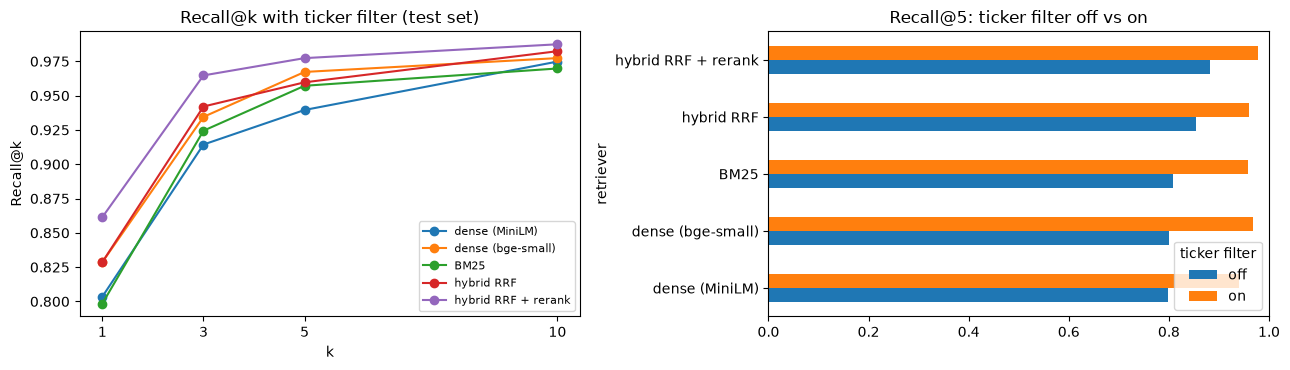

,"R@5 (hybrid+rerank, filter on)",questions
qtype,,
calculation,0.979167,48
derived_calculation,0.993289,149
numeric_lookup,0.970000,100
text_lookup,0.960000,100


In [17]:
RETRIEVERS = {"dense (MiniLM)": ("dense", dense_minilm), "dense (bge-small)": ("dense", dense_bge),
              "BM25": ("bm25", dense_bge), "hybrid RRF": ("hybrid", dense_bge),
              "hybrid RRF + rerank": ("hybrid_rerank", dense_bge)}
KS = (1, 3, 5, 10)
test_q = questions[questions.split == "test"]


def retrieval_eval(method, dense, use_filter, qs):
    first_hit, t0 = [], time.time()
    for r in qs.itertuples():
        got = [doc_ids[i] for i, _ in retrieve(r.question, r.ticker if use_filter else None, max(KS), method, dense)]
        rel = set(r.relevant_docs)
        first_hit.append(next((p for p, d in enumerate(got) if d in rel), None))
    out = {f"R@{k}": np.mean([h is not None and h < k for h in first_hit]) for k in KS}
    out["MRR@10"] = np.mean([0.0 if h is None else 1 / (h + 1) for h in first_hit])
    out["ms/query"] = 1000 * (time.time() - t0) / len(qs)
    return out, first_hit


ret_rows, ret_hits = [], {}
for name, (method, dense) in RETRIEVERS.items():
    for use_filter in (True, False):
        res, hits = retrieval_eval(method, dense, use_filter, test_q)
        ret_rows.append({"retriever": name, "ticker filter": "on" if use_filter else "off", **res})
        ret_hits[(name, use_filter)] = hits
retrieval_table = pd.DataFrame(ret_rows)
display(retrieval_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name in RETRIEVERS:
    row = retrieval_table[(retrieval_table.retriever == name) & (retrieval_table["ticker filter"] == "on")].iloc[0]
    axes[0].plot(KS, [row[f"R@{k}"] for k in KS], marker="o", label=name)
axes[0].set(title="Recall@k with ticker filter (test set)", xlabel="k", ylabel="Recall@k", xticks=KS)
axes[0].legend(fontsize=8)
piv = retrieval_table.pivot(index="retriever", columns="ticker filter", values="R@5").loc[list(RETRIEVERS)]
piv[["off", "on"]].plot.barh(ax=axes[1], title="Recall@5: ticker filter off vs on")
axes[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

hits5 = pd.Series([h is not None and h < 5 for h in ret_hits[("hybrid RRF + rerank", True)]], index=test_q.index)
display(test_q.assign(hit=hits5).groupby("qtype").hit.agg(["mean", "size"])
        .rename(columns={"mean": "R@5 (hybrid+rerank, filter on)", "size": "questions"}))

### 5b. Tools: `search_filings` and a sandboxed `run_python`

*Builds on `Agentic_app/relay_ops/tools.py` from Module 4 (`run_python`, `search_knowledge_base`) and the PAL
cell of the Module 2 `Structured_Generation_Lab`.*

**Program-of-thought.** The model writes the arithmetic as Python and an interpreter computes it, so no
multiplication is ever done "in tokens".

The lab's `run_python` ran `exec` *inside* the agent's process and guarded it with banned substrings. That
design has three problems:
- `while True: pass` hangs the whole agent.
- Harmless names such as `evaluation` are rejected, because they contain `eval`.
- `rev = 1,234.5` silently builds a tuple.

Our version (design choice D5) instead:
1. Parses the code and checks every syntax node against an **allow-list**. Allowed: arithmetic, assignments,
   comparisons, `for`, comprehensions, f-strings, and calls only to safe built-ins and `math.*`. Rejected:
   imports, `while`, function and class definitions, `lambda`, and any attribute other than `math.<name>`.
2. Strips thousands separators inside number literals, rewrites a trailing expression to `answer = ...`, and
   runs the code in a **separate `python -I` process with a 5 s timeout**.
3. Returns errors as text the agent can read and recover from, not as exceptions.

This isolates hangs and crashes. It is *not* an OS-level security sandbox (see section 9).

In [18]:
import ast

from langchain_core.tools import tool

SANDBOX_TIMEOUT_S = 5
SAFE_CALLS = {"abs", "round", "min", "max", "sum", "len", "float", "int", "pow", "range", "print", "sorted", "list"}
ALLOWED_NODES = (ast.Module, ast.Expr, ast.Assign, ast.AugAssign, ast.Name, ast.Load, ast.Store, ast.Constant,
                 ast.BinOp, ast.UnaryOp, ast.operator, ast.unaryop, ast.Compare, ast.cmpop, ast.BoolOp, ast.boolop,
                 ast.IfExp, ast.Call, ast.keyword, ast.Attribute, ast.List, ast.Tuple, ast.Subscript, ast.Slice,
                 ast.For, ast.Pass, ast.comprehension, ast.ListComp, ast.GeneratorExp, ast.JoinedStr,
                 ast.FormattedValue)
SANDBOX_RUNNER = r"""
import builtins, contextlib, io, json, math, sys
safe = {n: getattr(builtins, n) for n in sys.argv[1].split(",")}
ns, buf = {"__builtins__": safe, "math": math}, io.StringIO()
with contextlib.redirect_stdout(buf):
    exec(compile(sys.stdin.read(), "<run_python>", "exec"), ns)
ans = ns.get("answer")
print(json.dumps({"stdout": buf.getvalue()[-1500:],
                  "answer": ans if isinstance(ans, (int, float, str, type(None))) else repr(ans)}))
"""


def check_sandbox_code(tree):
    for node in ast.walk(tree):
        if not isinstance(node, ALLOWED_NODES):
            raise ValueError(f"{type(node).__name__} is not allowed in the sandbox")
        if isinstance(node, ast.Attribute) and not (isinstance(node.value, ast.Name) and node.value.id == "math"
                                                    and not node.attr.startswith("_")):
            raise ValueError("only math.<function> attributes are allowed")
        if isinstance(node, ast.Name) and node.id.startswith("__"):
            raise ValueError("dunder names are not allowed")
        if isinstance(node, ast.Call) and isinstance(node.func, ast.Name) and node.func.id not in SAFE_CALLS:
            raise ValueError(f"calling {node.func.id}() is not allowed; use arithmetic, math.* or {sorted(SAFE_CALLS)}")
        if isinstance(node, ast.BinOp) and isinstance(node.op, ast.Pow):
            exp = node.right.operand if isinstance(node.right, ast.UnaryOp) else node.right
            small_const = isinstance(exp, ast.Constant) and isinstance(exp.value, (int, float)) and abs(exp.value) <= 100
            if not (small_const or isinstance(exp, ast.Name)):
                raise ValueError("exponent too large (use a number up to 100 or a variable)")


def prepare_code(code):
    code = code.strip().strip("`").strip()
    code = re.sub(r"^python\s*\n", "", code)                                  # tolerate ```python fences
    code = re.sub(r"(?<![\w.])(\d{1,3}(?:,\d{3})+)(?![\d,])",                   # 1,234.5 -> 1234.5
                  lambda m: m.group(1).replace(",", ""), code)
    tree = ast.parse(code)
    check_sandbox_code(tree)
    if tree.body and isinstance(tree.body[-1], ast.Expr) and not (
            isinstance(tree.body[-1].value, ast.Call) and getattr(tree.body[-1].value.func, "id", "") == "print"):
        tree.body[-1] = ast.Assign(targets=[ast.Name("answer", ast.Store())], value=tree.body[-1].value)
        ast.fix_missing_locations(tree)
    return ast.unparse(tree)


def fmt_number(x):
    if isinstance(x, float):
        if not math.isfinite(x):
            return str(x)
        x = round(x, 6)
        return f"{x:,.6f}".rstrip("0").rstrip(".")
    return f"{x:,}" if isinstance(x, int) else str(x)


def run_python_code(code):
    try:
        prepared = prepare_code(code)
    except SyntaxError as e:
        return f"Error: invalid Python syntax ({e.msg}, line {e.lineno})."
    except ValueError as e:
        return f"Error: {e}."
    try:
        proc = subprocess.run([sys.executable, "-I", "-X", "utf8", "-c", SANDBOX_RUNNER, ",".join(sorted(SAFE_CALLS))],
                              input=prepared, capture_output=True, text=True, encoding="utf-8",
                              timeout=SANDBOX_TIMEOUT_S)
    except subprocess.TimeoutExpired:
        return f"Error: the code ran longer than {SANDBOX_TIMEOUT_S} s and was stopped."
    if proc.returncode != 0:
        last = (proc.stderr.strip().splitlines() or ["unknown error"])[-1]
        return f"Error while running the code: {last}"
    out = json.loads(proc.stdout.strip().splitlines()[-1])
    parts = [out["stdout"].strip()] if out["stdout"].strip() else []
    if out["answer"] is not None:
        parts.append(f"answer = {fmt_number(out['answer'])}")
    return "\n".join(parts) or "The code ran but produced no output. Assign the result to `answer` or print it."


@tool
def run_python(code: str) -> str:
    """Calculator. Runs a short Python snippet and returns the result. Use it for ANY arithmetic instead of computing
    in your head. Write plain Python with the numbers copied from the passages, for example:
    answer = (52527 - 46921) / 46921 * 100
    Only arithmetic, math functions, round, min, max, sum and print are available. No imports."""
    return run_python_code(code)


SANDBOX_TESTS = {
    "answer = 52527 - 46921": "answer = 5,606",
    "52,527 - 46,921": "answer = 5,606",
    "round((12508 - 10537) / 10537 * 100, 2)": "answer = 18.71",
    "rev = 1,234.5\nrev * 2": "answer = 2,469",
    "print(f'{1234.5 * 0.17:.2f}')": "209.87",
    "math.sqrt(16)": "answer = 4",
    "import os": "Error: Import is not allowed in the sandbox.",
    "open('x.txt')": "Error: calling open() is not allowed",
    "().__class__.__bases__": "Error: only math.<function> attributes are allowed.",
    "while True: pass": "Error: While is not allowed in the sandbox.",
    "for i in range(10**12): pass": "Error: the code ran longer than 5 s and was stopped.",
    "1 / 0": "Error while running the code: ZeroDivisionError: division by zero",
    "10 ** 10 ** 8": "Error: exponent too large",
    "x = 1.07\nx ** 3": "answer = 1.225043",
}
for code, expected in SANDBOX_TESTS.items():
    got = run_python_code(code)
    assert got.startswith(expected), f"{code!r}: expected {expected!r}, got {got!r}"
print(f"sandbox tests passed ({len(SANDBOX_TESTS)} cases)")

sandbox tests passed (14 cases)


`search_filings` wraps the 5a retriever (hybrid + rerank, top 5). Each passage starts with its id, as in
`[D01234 | NVDA]`, so the agent can cite its source and we can measure in-system recall from the trace.

The ticker the analyst selected is the default filter. A ticker the agent passes explicitly overrides it, and an
unknown ticker returns the list of valid ones. For the "ticker filter off" ablation, the tool ignores tickers
and searches every company.

In [19]:
PASSAGE_ID_RE = re.compile(r"\[(D\d{5}) \|")
MAX_PASSAGE_CHARS = 2000      # only 2 passages are longer; keeps one search result well inside the context window


def make_search_tool(default_ticker=None, use_filter=True, k=CONFIG["top_k"]):
    seen = set()

    @tool
    def search_filings(query: str, ticker: str = "") -> str:
        """Search the 10-K filing passages. Give a short search query, plus the company ticker such as NVDA.
        Returns the most relevant passages. Each passage starts with its id in square brackets; cite that id."""
        key = (norm_text(query), (ticker or "").upper())
        if key in seen:      # ReAct's most common failure is looping on the same search
            return "You already ran this exact search. Use the passages above, or search with different words."
        seen.add(key)
        t = None
        if use_filter:
            t = (ticker or default_ticker or "").strip().upper() or None
            if t and t not in ticker_rows:
                return f"Error: unknown ticker {t!r}. Valid tickers: {', '.join(sorted(ticker_rows))}."
        hits = retrieve(query, t, k=k)
        if not hits:
            return "No passages found."
        return "\n\n".join(f"[{doc_ids[i]} | {doc_ticker[i]}] {doc_text[i][:MAX_PASSAGE_CHARS]}" for i, _ in hits)

    return search_filings


demo_search = make_search_tool(default_ticker="DAL")
print(demo_search.invoke({"query": "total operating expenses 2023 2022"})[:700])
print(demo_search.invoke({"query": "revenue", "ticker": "DELTA"}))
print(demo_search.invoke({"query": "total operating expenses 2023 2022"}))

[D04105 | DAL] In 2023, Delta Air Lines' total operating expenses were $52,527 million, up from $46,921 million in 2022, marking a 12% increase.

[D04099 | DAL] Total non-operating income was $87 million in 2023 compared to total non-operating expense of $1.7 billion in 2022 primarily due to mark-to-market gains on certain of our equity investments and lower interest expense as a result of our debt reduction initiatives.

[D04098 | DAL] Total operating expense increased $5.6 billion, or 12%, compared to 2022, primarily resulting from higher employee related costs from increased wages and profit sharing, pilot agreement and related expenses and higher volume-related expenses associated with t
Error: unknown ticker 'DELTA'. Valid tickers: AAPL, ABBV, ABNB, AMC, AMD, AMZN, AVGO, AXP, AZO, BAC, BRK-A, CAT, CB, CMCSA, CMG, COST, CRM, CVS, CVX, DAL, DLTR, DVA, EA, EBAY, EFX, ENPH, ETSY, F, FDX, GILD, GIS, GM, GME, GOOGL, GRMN, GS, HAS, HD, HLT, HPE, HPQ, HSY, HUM, IBM, ICE, INTU, IRM, JNJ, J

### 5b (continued). The ReAct agent in LangGraph

*Builds on `build_react_agent` (`Agentic_app/relay_ops/graph.py`) and `ainvoke_requiring_tool` (`llm.py`) from
Module 4.*

**ReAct** alternates *reasoning* with *acting*: the model either calls a tool, whose result comes back as an
observation, or gives its final answer. Tools are called natively: Ollama returns structured `tool_calls`, so
no text needs parsing.

The graph adds the following harness rules around the model:
- **Step limit.** `steps` counts model turns. Once it reaches `MAX_STEPS` (6), the `finalize` node makes the model
  answer from what it already retrieved, without tools. LangGraph's `recursion_limit` is a second backstop.
- **Tool errors.** These become observations (`ToolNode(handle_tool_errors=True)`), and the sandbox returns errors
  as text, so the agent can recover.
- **Guard node.** Before an answer is accepted, it checks two things and may nudge once each:
  1. *Search first.* No answering from memory. Ollama ignores `tool_choice`, so the harness enforces this; the
     rule comes from the lab.
  2. *Calculator check.* The draft answer contains a number and `run_python` was never called. The model is
     asked to compute the figure with the tool if
     - the number appears in no retrieved passage (so it was computed in the model's head), or
     - the question asks for a change, total, ratio or percentage (a keyword rule on the question). This catches
       answers that copy a figure the passage states but that answers a different question, for example a
       percentage of sales when the question asks for a percentage of cost. It also catches answers that list
       the two figures without combining them.

     Each nudge fires at most once. On dev, the model often answered the second nudge with mental arithmetic
     instead of a tool call, so the first nudge may follow it when the rewritten answer contains such a number.
     The Module 4 lab recorded the agent skipping the calculator. Both checks use only information available at
     answer time, never the gold answer.

The prompt's worked example uses an invented company, so no test question leaks into it.

In [20]:
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode
from langgraph.types import Command

PROMPT_RULES = {
    True: ("2. Find the exact figures in the passages. If the question needs ANY arithmetic (a difference, change, "
           "percentage, ratio, total or share), call run_python with the numbers copied from the passages. "
           "Never do arithmetic in your head."),
    False: "2. Find the exact figures in the passages. If the question needs arithmetic, compute it carefully.",
}
EXAMPLE = {
    True: """Example (an invented company):
User: Company ticker: ACME. Question: By how much did ACME's revenue grow from 2022 to 2023?
You call search_filings(query="revenue 2023 2022", ticker="ACME") and read:
[D99999 | ACME] Revenue was $1,250.4 million in 2023 compared with $1,102.9 million in 2022.
You call run_python(code="answer = 1250.4 - 1102.9") and read: answer = 147.5
Answer: Revenue grew by $147.5 million, from $1,102.9 million in 2022 to $1,250.4 million in 2023.
Source: [D99999]""",
    False: """Example (an invented company):
User: Company ticker: ACME. Question: What was ACME's revenue in 2023?
You call search_filings(query="revenue 2023", ticker="ACME") and read:
[D99999 | ACME] Revenue was $1,250.4 million in 2023 compared with $1,102.9 million in 2022.
Answer: Revenue was $1,250.4 million in 2023.
Source: [D99999]""",
}


def system_prompt(calculator=True):
    tools_line = ("Tools: search_filings finds passages from the company's 10-K filing; run_python is a calculator."
                  if calculator else "Tool: search_filings finds passages from the company's 10-K filing.")
    return f"""You are a careful financial analyst answering questions about a company's 10-K filing.
{tools_line}
Rules:
1. Always call search_filings first. Never answer from memory.
{PROMPT_RULES[calculator]}
3. If the passages do not contain the answer, search again with different words (at most 3 searches). If it is
still not there, say that the filing passages do not contain the answer.
4. Finish with exactly two lines:
Answer: <one or two sentences with the figure and its unit>
Source: [<passage id>]

{EXAMPLE[calculator]}"""


NUDGE_SEARCH = "You must call search_filings before answering. Do not answer from memory."
NUDGE_CALC = ("Your answer contains a number that is not written in the retrieved passages. Compute it with "
              "run_python using the numbers from the passages, then give the final answer in the required format.")
NUDGE_CALC_Q = ("This question asks for a calculated figure (a change, total, ratio or percentage). Call run_python now "
                "with the numbers from the passages, for example run_python(code=\"answer = (a - b) / b * 100\") with "
                "a and b replaced by the figures. Give the final answer in the required format only after it returns.")
CALC_INTENT_RE = re.compile(
    r"\b(?:combined|total|sum|difference|chang(?:e|ed)|increas(?:e|ed)|decreas(?:e|ed)|grow|grew|growth|"
    r"declin(?:e|ed)|ratio|percent(?:age)?|share|proportion|by how much|how much (?:more|less|higher|lower))\b", re.I)
FINALIZE = ("Step limit reached. Do not call any tools. Give your best final answer now from the passages above, "
            "in the required two-line format.")


class AgentState(MessagesState):
    steps: int
    nudges: list


def answer_numbers_unsupported(text, passages):
    """Numbers in the draft answer that no retrieved passage states (up to presentation)."""
    pool = [n["value"] for p in passages for n in extract_numbers(p)]
    return [n["value"] for n in extract_numbers(text)
            if not any(same_up_to_presentation(n["value"], v) for v in pool)]


def build_agent(ticker=None, calculator=True, use_filter=True, guard=True, temperature=0.0, seed=SEED):
    tools = [make_search_tool(ticker if use_filter else None, use_filter=use_filter)]
    if calculator:
        tools.append(run_python)
    llm = get_llm(CONFIG["agent_model"], temperature=temperature, seed=seed, num_ctx=CONFIG["agent_num_ctx"])
    model, plain = llm.bind_tools(tools), llm
    sys_msg = SystemMessage(system_prompt(calculator))

    def agent(state: AgentState):
        reply = model.invoke([sys_msg] + state["messages"])
        return {"messages": [reply], "steps": state.get("steps", 0) + 1}

    def route_after_agent(state: AgentState):
        if state["messages"][-1].tool_calls:
            return "tools" if state["steps"] < CONFIG["max_steps"] else "finalize"
        return "guard"

    def finalize(state: AgentState):
        reply = plain.invoke([sys_msg] + state["messages"] + [HumanMessage(FINALIZE)])
        return {"messages": [reply], "nudges": state.get("nudges", []) + ["step_limit"]}

    def guard_node(state: AgentState):
        nudges = state.get("nudges", [])
        msgs = state["messages"]
        passages = [m.content for m in msgs if isinstance(m, ToolMessage) and m.name == "search_filings"]
        used_calc = any(m.name == "run_python" for m in msgs if isinstance(m, ToolMessage))
        if guard and not passages and nudges.count("search") < 2:
            return Command(goto="agent", update={"messages": [HumanMessage(NUDGE_SEARCH)], "nudges": nudges + ["search"]})
        draft = msgs[-1].content.split("Source:")[0]
        # Each calculator nudge fires at most once. "calc" may follow "calc_question": the model often answers that
        # nudge with mental arithmetic, which then shows up as an unsupported number.
        if guard and calculator and not used_calc and passages and extract_numbers(draft):
            if "calc" not in nudges and answer_numbers_unsupported(draft, passages):
                return Command(goto="agent", update={"messages": [HumanMessage(NUDGE_CALC)], "nudges": nudges + ["calc"]})
            if not {"calc", "calc_question"} & set(nudges) and CALC_INTENT_RE.search(msgs[0].content.split("Question:")[-1]):
                return Command(goto="agent", update={"messages": [HumanMessage(NUDGE_CALC_Q)],
                                                     "nudges": nudges + ["calc_question"]})
        return Command(goto=END)

    g = StateGraph(AgentState)
    g.add_node("agent", agent)
    g.add_node("tools", ToolNode(tools, handle_tool_errors=True))
    g.add_node("finalize", finalize)
    g.add_node("guard", guard_node, destinations=("agent", END))
    g.add_edge(START, "agent")
    g.add_conditional_edges("agent", route_after_agent, ["tools", "finalize", "guard"])
    g.add_edge("tools", "agent")
    g.add_edge("finalize", END)
    return g.compile()


ANSWER_RE = re.compile(r"Answer:\s*(.+?)(?:\n\s*Source:|$)", re.S)
SOURCE_RE = re.compile(r"Source:\s*\[?\s*(D\d{5})")


def run_agent(question, ticker=None, **agent_kw):
    """Run the agent on one question; return the parsed answer plus everything the evaluation needs."""
    app = build_agent(ticker=ticker, **agent_kw)
    user = f"Company ticker: {ticker}\nQuestion: {question}" if ticker and agent_kw.get("use_filter", True) else question
    t0 = time.time()
    out = app.invoke({"messages": [HumanMessage(user)], "steps": 0, "nudges": []},
                     {"recursion_limit": 4 * CONFIG["max_steps"] + 10})
    latency = time.time() - t0
    msgs = out["messages"]
    final = msgs[-1].content.strip()
    m_ans, m_src = ANSWER_RE.search(final), SOURCE_RE.search(final)
    calls = [c for m in msgs if isinstance(m, AIMessage) for c in (m.tool_calls or [])]
    tool_msgs = [m for m in msgs if isinstance(m, ToolMessage)]
    usage = [m.usage_metadata or {} for m in msgs if isinstance(m, AIMessage)]
    return {
        "answer": m_ans.group(1).strip() if m_ans else final,
        "raw_final": final,
        "cited_doc": m_src.group(1) if m_src else None,
        "tool_calls": [{"name": c["name"], "args": c["args"]} for c in calls],
        "retrieved_docs": sorted({d for m in tool_msgs if m.name == "search_filings" for d in PASSAGE_ID_RE.findall(m.content)}),
        "tool_errors": sum(m.content.startswith("Error") for m in tool_msgs),
        "llm_calls": sum(isinstance(m, AIMessage) for m in msgs),
        "nudges": out.get("nudges", []),
        "steps": out.get("steps", 0),
        "input_tokens": sum(u.get("input_tokens", 0) for u in usage),
        "output_tokens": sum(u.get("output_tokens", 0) for u in usage),
        "latency_s": round(latency, 2),
        "trace": [{"role": type(m).__name__, "content": m.content[:1500],
                   "tool_calls": [{"name": c["name"], "args": c["args"]} for c in (getattr(m, "tool_calls", None) or [])],
                   "name": getattr(m, "name", None)} for m in msgs],
    }


print(build_agent(ticker="DAL").get_graph().draw_mermaid())


def show_trace(rec):
    for step in rec["trace"]:
        if step["role"] == "HumanMessage":
            print(f"USER   {step['content'][:300]}")
        elif step["role"] == "AIMessage":
            for c in step["tool_calls"]:
                print(f"ACT    {c['name']}({json.dumps(c['args'])[:300]})")
            if step["content"]:
                print(f"MODEL  {step['content'][:400]}")
        elif step["role"] == "ToolMessage":
            print(f"OBS    [{step['name']}] {step['content'][:300]}")
    print(f"-> answer: {rec['answer']} | cited {rec['cited_doc']} | {rec['latency_s']}s, {rec['llm_calls']} LLM calls, "
          f"nudges {rec['nudges']}")

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	tools(tools)
	finalize(finalize)
	guard(guard)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> finalize;
	agent -.-> guard;
	agent -.-> tools;
	guard -.-> __end__;
	guard -.-> agent;
	tools --> agent;
	finalize --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**The agent on dev questions.** These are 2 questions of each type, from dev only. This is where the prompt
and guards were checked; test questions are never used for tuning.

In [21]:
dev_q = questions[questions.split == "dev"]
dev_sample = pd.concat([g.sample(2, random_state=SEED) for _, g in dev_q.groupby("qtype")])
dev_runs = []
for r in dev_sample.itertuples():
    rec = run_agent(r.question, r.ticker)
    dev_runs.append({"qtype": r.qtype, "calc_called": any(c["name"] == "run_python" for c in rec["tool_calls"]),
                     "gold_retrieved": bool(set(rec["retrieved_docs"]) & set(r.relevant_docs)),
                     "numeric_ok": (numeric_correct(rec["answer"], r.gold_numbers, r.gold_answer)
                                    if r.qtype in CALC_TYPES else None),
                     "latency_s": rec["latency_s"], "llm_calls": rec["llm_calls"]})
    print(f"\n=== [{r.qtype}] {r.question}\nGOLD   {r.gold_answer}")
    show_trace(rec)
display(pd.DataFrame(dev_runs))


=== [derived_calculation] What were the total interest paid by the company in 2022 and 2023 combined?
GOLD   $2,263 million
USER   Company ticker: KO
Question: What were the total interest paid by the company in 2022 and 2023 combined?
ACT    search_filings({"query": "interest paid 2022 2023", "ticker": "KO"})
OBS    [search_filings] [D03168 | KO] Total interest paid was $1,415 million, $848 million and $738 million in 2023, 2022 and 2021, respectively.

[D03141 | KO] Interest income was $907 million in 2023, compared to $449 million in 2022, an increase of $458 million, or 102%.

[D03143 | KO] Interest expense was $1,527 millio
MODEL  Answer: The total interest paid by the company in 2022 and 2023 combined was $848 million + $1,527 million = $2,375 million.
Source: [D03168]
USER   Your answer contains a number that is not written in the retrieved passages. Compute it with run_python using the numbers from the passages, then give the final answer in the required format.
ACT    run_pyt


=== [derived_calculation] By what percentage did the company's financing change from 2022 to 2023?
GOLD   -11.8%
USER   Company ticker: CB
Question: By what percentage did the company's financing change from 2022 to 2023?
ACT    search_filings({"query": "financing 2023 2022", "ticker": "CB"})
OBS    [search_filings] [D03757 | CB] For financing was $4.5 billion in 2023, compared to $5.1 billion and $4.4 billion in 2022 and 2021, respectively.

[D03756 | CB] The decrease of $653 million in 2023 compared to 2022 is primarily from lower long-term debt repayments of $525 million and lower common shares repurchased o
ACT    run_python({"code": "answer = (4500 - 5100) / 5100 * 100"})
OBS    [run_python] answer = -11.764706
MODEL  Answer: The company's financing decreased by 11.76%, from $5.1 billion in 2022 to $4.5 billion in 2023.  
Source: [D03757]
-> answer: The company's financing decreased by 11.76%, from $5.1 billion in 2022 to $4.5 billion in 2023. | cited D03757 | 4.27s, 3 LLM calls,


=== [numeric_lookup] What was the ending balance of liabilities for contingent consideration in 2023, and how did it compare to the previous year?
GOLD   The ending balance was $1,092 million in 2023, compared to $1,120 million in 2022.
USER   Company ticker: JNJ
Question: What was the ending balance of liabilities for contingent consideration in 2023, and how did it compare to the previous year?
ACT    search_filings({"query": "ending balance liabilities contingent consideration 2023", "ticker": "JNJ"})
OBS    [search_filings] [D06451 | JNJ] The ending balance of liabilities for contingent consideration was $1,092 million in 2023, compared to $1,120 million in 2022.

[D02571 | JNJ] Total borrowings at the end of 2023 and 2022 were $29.3 billion and $39.6 billion, respectively. The decrease in the debt balance was due to t
MODEL  Answer: The ending balance of liabilities for contingent consideration was $1,092 million in 2023, a decrease of $28 million from $1,120 million in 2022.  
S


=== [numeric_lookup] What is the valuation allowance of the company as of January 31, 2023?
GOLD   $633 million
USER   Company ticker: CRM
Question: What is the valuation allowance of the company as of January 31, 2023?
ACT    search_filings({"query": "valuation allowance January 31 2023", "ticker": "CRM"})
OBS    [search_filings] [D02185 | CRM] The Company had a valuation allowance of $633 million as of January 31, 2023.

[D02187 | CRM] The increase in the valuation allowance during fiscal 2023 was primarily due to state tax credits and certain U.S foreign tax credits that are not expected to be realized.

[D02170 | CRM] In 
MODEL  Answer: The valuation allowance of the company as of January 31, 2023, was $633 million.  
Source: [D02185]
-> answer: The valuation allowance of the company as of January 31, 2023, was $633 million. | cited D02185 | 3.44s, 2 LLM calls, nudges []



=== [text_lookup] What is the purpose of Tesla's used vehicle business with regards to new vehicle sales?
GOLD   Tesla's used vehicle business supports new vehicle sales by integrating the trade-in of a customer's existing Tesla or non-Tesla vehicle with the sale of a new or used Tesla vehicle.
USER   Company ticker: TSLA
Question: What is the purpose of Tesla's used vehicle business with regards to new vehicle sales?
ACT    search_filings({"query": "purpose used vehicle business new vehicle sales", "ticker": "TSLA"})
OBS    [search_filings] [D00184 | TSLA] Used Vehicle Sales Our used vehicle business supports new vehicle sales by integrating the trade-in of a customer’s existing Tesla or non-Tesla vehicle with the sale of a new or used Tesla vehicle. The Tesla and non-Tesla vehicles we acquire as trade-ins are subsequently remarketed, 
MODEL  Answer: The purpose of Tesla's used vehicle business is to support new vehicle sales by integrating the trade-in of a customer’s existing Tesla


=== [text_lookup] What factors are typically considered when determining the stand-alone selling price (SSP) range if it isn't directly observable?
GOLD   The SSP range is determined using information that may include pricing practices or other observable inputs.
USER   Company ticker: CRM
Question: What factors are typically considered when determining the stand-alone selling price (SSP) range if it isn't directly observable?
ACT    search_filings({"query": "stand-alone selling price SSP range factors not directly observable", "ticker": "CRM"})
OBS    [search_filings] [D02114 | CRM] If SSP is not directly observable, for example when pricing is highly variable, we use a range of SSP. We determine the SSP range using information that may include pricing practices or other observable inputs.

[D02164 | CRM] The Company determines SSP by considering its overall pric
MODEL  Answer: Factors typically considered when determining the stand-alone selling price (SSP) range include pricing pra

,qtype,calc_called,gold_retrieved,numeric_ok,latency_s,llm_calls
0,derived_calculation,True,True,False,4.97,4
1,derived_calculation,True,True,True,4.27,3
2,numeric_lookup,True,True,None,5.10,4
3,numeric_lookup,False,True,None,3.44,2
4,text_lookup,False,True,None,3.83,2
5,text_lookup,False,True,None,3.68,2


### 5c. Fine-tuning

Not required by the brief, so nothing is fine-tuned. The system improves the model's behaviour through tools,
retrieval and harness rules instead.

## 6. Evaluation

Every condition runs on the same evaluation set (4.1) with the same agent model, and is scored by the same judge
and numeric metric.

| Condition | What it is |
|---|---|
| **B0** closed-book | the model alone (section 4) |
| **B1** plain RAG | top 5 passages from 5a (hybrid + rerank, ticker filter), answered with the Module 3 RAG prompt |
| **B2** RAG + CoT | the same passages; the model reasons step by step and does the arithmetic in text |
| **S** full agent | ReAct with `search_filings` + `run_python` + guards |
| **A1** S, ticker filter off | the agent gets no ticker and searches every company |
| **A2** S, calculator off | the agent has only `search_filings` |

In [22]:
RAG_PLAIN = """Answer the question using ONLY the passages below. If the answer is not in the passages, say "I don't have that information."
Passages:
{passages}

Question: {question}
Finish with exactly two lines:
Answer: <one or two sentences with the figure and its unit>
Source: [<passage id>]"""
RAG_COT = """Answer the question using ONLY the passages below. If the answer is not in the passages, say "I don't have that information."
Passages:
{passages}

Question: {question}
Think step by step: first quote the figures you need from the passages, then do any arithmetic step by step.
Then finish with exactly two lines:
Answer: <one or two sentences with the figure and its unit>
Source: [<passage id>]"""


def format_passages(hits):
    return "\n\n".join(f"[{doc_ids[i]} | {doc_ticker[i]}] {doc_text[i][:MAX_PASSAGE_CHARS]}" for i, _ in hits)


def parse_final(text):
    answers = ANSWER_RE.findall(text)
    src = SOURCE_RE.findall(text)
    return (answers[-1].strip() if answers else text.strip()), (src[-1] if src else None)


def rag_answer(r, template):
    hits = retrieve(r.question, r.ticker, k=CONFIG["top_k"])
    text, cost = answer_from_llm(agent_llm, template.format(passages=format_passages(hits), question=r.question))
    answer, cited = parse_final(text)
    return {"answer": answer, "raw_final": text, "cited_doc": cited,
            "retrieved_docs": [doc_ids[i] for i, _ in hits], **cost}


def agent_condition(**kw):
    return lambda r: run_agent(r.question, r.ticker, **kw)


CONDITIONS = {   # name: (answer function, version of the system that produced the cached predictions)
    "B0_closed_book": (closed_book, BASELINE_VERSION),
    "B1_plain_rag": (lambda r: rag_answer(r, RAG_PLAIN), BASELINE_VERSION),
    "B2_rag_cot": (lambda r: rag_answer(r, RAG_COT), BASELINE_VERSION),
    "S_agent": (agent_condition(), AGENT_VERSION),
    "A1_agent_no_ticker_filter": (agent_condition(use_filter=False), AGENT_VERSION),
    "A2_agent_no_calculator": (agent_condition(calculator=False), AGENT_VERSION),
}
for name, (fn, version) in CONDITIONS.items():
    if name not in scored:
        scored[name] = score(name, run_condition(name, fn, version))
print("scored:", list(scored))

scored: ['B0_closed_book', 'B1_plain_rag', 'B2_rag_cot', 'S_agent', 'A1_agent_no_ticker_filter', 'A2_agent_no_calculator']


,judge acc,judge: text_lookup,judge: numeric_lookup,judge: calculation,judge: derived_calculation,numeric acc (calc),calculator used (calc),calculator used (lookup),gold passage retrieved,citation acc,refusal rate,s / question,LLM calls / q,tokens / q,no judge verdict
condition,,,,,,,,,,,,,,,
B0_closed_book,0.111,0.34,0.06,0.000,0.027,0.025,NaN,NaN,NaN,NaN,0.471,1.245,1.000,136.632,0
B1_plain_rag,0.698,0.79,0.86,0.771,0.503,0.604,NaN,NaN,0.977,0.798,0.083,1.177,1.000,454.350,0
B2_rag_cot,0.758,0.87,0.80,0.729,0.664,0.721,NaN,NaN,0.977,0.861,0.086,4.737,1.000,652.060,0
S_agent,0.748,0.93,0.85,0.729,0.564,0.645,0.584,0.040,0.977,0.849,0.055,5.368,3.043,3416.368,0
A1_agent_no_ticker_filter,0.569,0.70,0.64,0.667,0.403,0.482,0.442,0.055,0.806,0.610,0.176,25.476,3.358,3955.224,0
A2_agent_no_calculator,0.741,0.95,0.89,0.708,0.510,0.589,0.000,0.000,0.982,0.854,0.071,4.103,2.028,1490.544,0


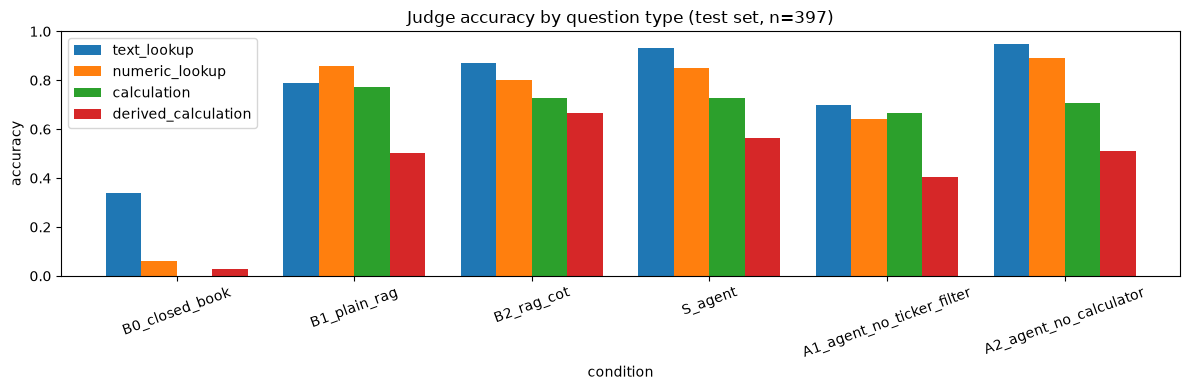

In [23]:
TYPE_ORDER = ["text_lookup", "numeric_lookup", "calculation", "derived_calculation"]
HAS_TOOLS = {"S_agent", "A1_agent_no_ticker_filter", "A2_agent_no_calculator"}


def summarize(name, p):
    acc = lambda s: s.astype(float).mean()          # None (no verdict) is excluded from the mean
    calc, look = p[p.qtype.isin(CALC_TYPES)], p[~p.qtype.isin(CALC_TYPES)]
    row = {"condition": name, "judge acc": acc(p.judge_ok)}
    row |= {f"judge: {t}": acc(p.loc[p.qtype == t, "judge_ok"]) for t in TYPE_ORDER}
    row["numeric acc (calc)"] = acc(calc.numeric_ok)
    row["calculator used (calc)"] = calc.calc_called.mean() if name in HAS_TOOLS else np.nan
    row["calculator used (lookup)"] = look.calc_called.mean() if name in HAS_TOOLS else np.nan
    row["gold passage retrieved"] = p.gold_retrieved.astype(float).mean()
    row["citation acc"] = p.cited_ok.mean() if name != "B0_closed_book" else np.nan
    row["refusal rate"] = p.refusal.mean()
    row["s / question"] = p.latency_s.mean()
    row["LLM calls / q"] = p.llm_calls.mean()
    row["tokens / q"] = (p.input_tokens + p.output_tokens).mean()
    row["no judge verdict"] = int(p.judge_ok.isna().sum())
    return row


results = pd.DataFrame([summarize(n, p) for n, p in scored.items()]).set_index("condition")
display(results.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
results[[f"judge: {t}" for t in TYPE_ORDER]].rename(columns=lambda c: c.replace("judge: ", "")).plot.bar(ax=ax, width=0.8)
ax.set(title=f"Judge accuracy by question type ({'quick subset' if QUICK_RUN else 'test set'}, n={len(eval_q)})",
       ylabel="accuracy", ylim=(0, 1))
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**How sure are these numbers?** With a few hundred questions, a gap of a few points can be noise. We give each
accuracy a 95% bootstrap interval (10,000 resamples of the questions). Every condition answers the same questions,
so we compare S with each other condition **paired**: the interval is for the per-question difference, and the
p-value is McNemar's exact test on the questions where exactly one of the two is right. Questions without a
verdict are left out of a comparison.

In [24]:
from scipy.stats import binomtest

N_BOOT = 10_000
boot_rng = np.random.default_rng(SEED)


def in_group(p, group):
    """'lookup' = text + numeric lookups; 'calculation' = real + derived calculations."""
    if group == "all":
        return p
    return p[p.qtype.isin(CALC_TYPES)] if group == "calculation" else p[~p.qtype.isin(CALC_TYPES)]


def outcome(p, col):
    """0/1 per qid, verdict-less rows dropped."""
    s = p.set_index("qid")[col]
    return s[s.notna()].astype(float)


def boot_ci(x):
    x = np.asarray(x, dtype=float)
    means = x[boot_rng.integers(0, len(x), size=(N_BOOT, len(x)))].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def fmt_ci(x):
    lo, hi = boot_ci(x)
    return f"{np.mean(x):.3f} [{lo:.3f}, {hi:.3f}]"


METRICS = [("judge, all", "judge_ok", "all"), ("judge, lookup", "judge_ok", "lookup"),
           ("judge, calculation", "judge_ok", "calculation"), ("numeric, calculation", "numeric_ok", "calculation")]
ci_table = pd.DataFrame({name: {m: fmt_ci(outcome(in_group(p, g), col)) for m, col, g in METRICS}
                         for name, p in scored.items()}).T
ci_table.index.name = "condition (accuracy [95% CI])"
display(ci_table)

paired_rows = []
for other in ("B2_rag_cot", "B1_plain_rag", "A2_agent_no_calculator", "A1_agent_no_ticker_filter"):
    for m, col, g in METRICS:
        both = pd.concat([outcome(in_group(scored["S_agent"], g), col).rename("S"),
                          outcome(in_group(scored[other], g), col).rename("other")], axis=1, join="inner")
        diff = both.S - both.other
        lo, hi = boot_ci(diff)
        s_only, other_only = int((diff > 0).sum()), int((diff < 0).sum())
        p = binomtest(s_only, s_only + other_only, 0.5).pvalue if s_only + other_only else 1.0
        paired_rows.append({"S vs": other, "metric": m, "n": len(both), "S − other": round(diff.mean(), 3),
                            "95% CI": f"[{lo:.3f}, {hi:.3f}]", "only S right": s_only,
                            "only other right": other_only, "McNemar p": round(p, 4)})
paired = pd.DataFrame(paired_rows).set_index(["S vs", "metric"])
display(paired)

# The success targets of section 1, fixed before any test result
r5 = retrieval_table.set_index(["retriever", "ticker filter"]).loc[("hybrid RRF + rerank", "on"), "R@5"]
num_gap = paired.loc[("B2_rag_cot", "numeric, calculation"), "S − other"]
look_gap = paired.loc[("B1_plain_rag", "judge, lookup"), "S − other"]
calc_use = results.loc["S_agent", "calculator used (calc)"]
targets = pd.DataFrame([
    ("retrieval Recall@5 (hybrid + rerank, filter on)", "≥ 0.90", r5, r5 >= 0.90),
    ("numeric acc on calculation, S − B2", "≥ +0.15", num_gap, num_gap >= 0.15),
    ("judge acc on lookup, S − B1", "≥ −0.03", look_gap, look_gap >= -0.03),
    ("calculator used on calculation questions (S)", "≥ 0.90", calc_use, calc_use >= 0.90),
], columns=["target", "goal", "result", "met"]).set_index("target")
display(targets.round(3))

,"judge, all","judge, lookup","judge, calculation","numeric, calculation"
condition (accuracy [95% CI]),,,,
B0_closed_book,"0.111 [0.081, 0.144]","0.200 [0.145, 0.255]","0.020 [0.005, 0.041]","0.025 [0.005, 0.051]"
B1_plain_rag,"0.698 [0.652, 0.743]","0.825 [0.770, 0.875]","0.569 [0.503, 0.635]","0.604 [0.533, 0.670]"
B2_rag_cot,"0.758 [0.715, 0.798]","0.835 [0.780, 0.885]","0.680 [0.614, 0.746]","0.721 [0.655, 0.782]"
S_agent,"0.748 [0.703, 0.791]","0.890 [0.845, 0.930]","0.604 [0.538, 0.675]","0.645 [0.579, 0.711]"
A1_agent_no_ticker_filter,"0.569 [0.519, 0.617]","0.670 [0.605, 0.735]","0.467 [0.396, 0.538]","0.482 [0.411, 0.553]"
A2_agent_no_calculator,"0.741 [0.698, 0.783]","0.920 [0.880, 0.955]","0.558 [0.487, 0.629]","0.589 [0.518, 0.660]"


n  S − other  \
S vs                      metric                                 
B2_rag_cot                judge, all            397     -0.010   
                          judge, lookup         200      0.055   
                          judge, calculation    197     -0.076   
                          numeric, calculation  197     -0.076   
B1_plain_rag              judge, all            397      0.050   
                          judge, lookup         200      0.065   
                          judge, calculation    197      0.036   
                          numeric, calculation  197      0.041   
A2_agent_no_calculator    judge, all            397      0.008   
                          judge, lookup         200     -0.030   
                          judge, calculation    197      0.046   
                          numeric, calculation  197      0.056   
A1_agent_no_ticker_filter judge, all            397      0.179   
                          judge, lookup         200      0.220   
                          judge, calculation    197      0.137   
                          numeric, calculation  197      0.162   

                                                          95% CI  \
S vs                      metric                                   
B2_rag_cot                judge, all             [-0.050, 0.030]   
                          judge, lookup           [0.005, 0.105]   
                          judge, calculation    [-0.137, -0.015]   
                          numeric, calculation  [-0.132, -0.020]   
B1_plain_rag              judge, all              [0.008, 0.093]   
                          judge, lookup           [0.005, 0.125]   
                          judge, calculation     [-0.025, 0.096]   
                          numeric, calculation   [-0.020, 0.102]   
A2_agent_no_calculator    judge, all             [-0.025, 0.040]   
                          judge, lookup          [-0.070, 0.010]   
                          judge, calculation     [-0.005, 0.096]   
                          numeric, calculation    [0.010, 0.102]   
A1_agent_no_ticker_filter judge, all              [0.134, 0.224]   
                          judge, lookup           [0.155, 0.290]   
                          judge, calculation      [0.076, 0.198]   
                          numeric, calculation    [0.102, 0.223]   

                                                only S right  \
S vs                      metric                               
B2_rag_cot                judge, all                      30   
                          judge, lookup                   19   
                          judge, calculation              11   
                          numeric, calculation            10   
B1_plain_rag              judge, all                      47   
                          judge, lookup                   25   
                          judge, calculation              22   
                          numeric, calculation            22   
A2_agent_no_calculator    judge, all                      22   
                          judge, lookup                    5   
                          judge, calculation              17   
                          numeric, calculation            16   
A1_agent_no_ticker_filter judge, all                      85   
                          judge, lookup                   50   
                          judge, calculation              35   
                          numeric, calculation            38   

                                                only other right  McNemar p  
S vs                      metric                                             
B2_rag_cot                judge, all                          34     0.7080  
                          judge, lookup                        8     0.0522  
                          judge, calculation                  26     0.0201  
                          numeric, calculation                25     0.0167  
B1_plain_rag   

,goal,result,met
target,,,
"retrieval Recall@5 (hybrid + rerank, filter on)",≥ 0.90,0.977,True
"numeric acc on calculation, S − B2",≥ +0.15,-0.076,False
"judge acc on lookup, S − B1",≥ −0.03,0.065,True
calculator used on calculation questions (S),≥ 0.90,0.584,False


### 6.1 Is the judge trustworthy?

Teammate B labels a stratified sample of answers from B1, B2 and S **blind** (without seeing the judge's
verdict). We then report agreement and Cohen's κ against the combined verdict and against the LLM judge alone.

In [25]:
val_pool = pd.concat([scored[c].assign(condition=c) for c in ("B1_plain_rag", "B2_rag_cot", "S_agent")])
val_pool["answer_key"] = ["h" + hashlib.sha1(a.encode()).hexdigest()[:12] for a in val_pool.answer]   # Excel-safe id
val_sample = pd.concat([g.sample(min(20, len(g)), random_state=SEED) for _, g in val_pool.groupby("condition")])
export_once(val_sample[["condition", "qid", "answer_key", "question", "gold_answer", "answer"]].assign(human_correct=""),
            "judge_validation_to_label.csv")
val_path = LABELS / "judge_validation_labels.csv"
if val_path.exists():
    from sklearn.metrics import cohen_kappa_score
    hv = pd.read_csv(val_path)
    hv = hv[hv.human_correct.astype(str).str.strip().str.lower().isin(["yes", "no"])]
    hv["human"] = hv.human_correct.str.strip().str.lower() == "yes"
    n_labelled = len(hv)
    hv = hv.drop(columns="answer").merge(val_pool[["condition", "qid", "answer_key", "judge_ok", "llm_judge_ok"]],
                                         on=["condition", "qid", "answer_key"])
    if len(hv) != n_labelled:
        raise RuntimeError(f"{n_labelled - len(hv)} human labels in {val_path} are for answers that the current "
                           "predictions no longer contain (the system changed after labelling): re-label them")
    for col in ("judge_ok", "llm_judge_ok"):
        ok = hv[col].notna()
        print(f"{col:13s} vs human on {int(ok.sum())} answers: agreement {np.mean(hv.human[ok] == hv[col][ok].astype(bool)):.1%}, "
              f"kappa {cohen_kappa_score(hv.human[ok], hv[col][ok].astype(bool)):.2f}")
else:
    print(f"PENDING: {val_path} not provided yet, so judge agreement with humans is not computed")

kept existing artifacts\labels\judge_validation_to_label.csv (not overwritten)
PENDING: artifacts\labels\judge_validation_labels.csv not provided yet, so judge agreement with humans is not computed


### 6.2 Stretch goal: self-consistency on calculation questions

**Self-consistency** samples several reasoning paths at temperature > 0 and takes a majority vote over their
answers. We run the full agent 3 times (T = 0.7, different seeds) on every calculation question and vote on the
answer's first figure, rounded to 3 significant digits. The run whose figure won supplies the final answer and
citation. Cost is the sum of all 3 runs.

In [26]:
def vote_key(answer):
    nums = extract_numbers(answer)
    return float(f"{abs(nums[0]['value']):.3g}") if nums else None


def self_consistency(r, n=3):
    runs = [run_agent(r.question, r.ticker, temperature=0.7, seed=SEED + i) for i in range(1, n + 1)]
    keys = [vote_key(x["answer"]) for x in runs]
    counts = Counter(k for k in keys if k is not None)
    winner = max(counts, key=lambda k: (counts[k], -keys.index(k))) if counts else None
    chosen = runs[keys.index(winner)] if winner is not None else runs[0]
    return {**chosen, "votes": keys, "latency_s": round(sum(x["latency_s"] for x in runs), 2),
            "llm_calls": sum(x["llm_calls"] for x in runs), "input_tokens": sum(x["input_tokens"] for x in runs),
            "output_tokens": sum(x["output_tokens"] for x in runs)}


calc_q = eval_q[eval_q.qtype.isin(CALC_TYPES)]
scored["SC3_agent"] = score("SC3_agent", run_condition("SC3_agent", self_consistency, AGENT_VERSION, calc_q), calc_q)
s_calc = scored["S_agent"][scored["S_agent"].qtype.isin(CALC_TYPES)]
sc_table = pd.DataFrame([{"condition": n, "judge acc": p.judge_ok.astype(float).mean(),
                          "numeric acc": p.numeric_ok.astype(float).mean(), "s / question": p.latency_s.mean(),
                          "LLM calls / q": p.llm_calls.mean(), "tokens / q": (p.input_tokens + p.output_tokens).mean()}
                         for n, p in (("S_agent (greedy, 1 run)", s_calc), ("SC3_agent (3 runs, vote)", scored["SC3_agent"]))])
display(sc_table.set_index("condition").round(3))

,judge acc,numeric acc,s / question,LLM calls / q,tokens / q
condition,,,,,
"S_agent (greedy, 1 run)",0.604,0.645,5.989,3.619,4284.518
"SC3_agent (3 runs, vote)",0.614,0.660,16.758,10.604,12429.421


### 6.3 What the results say

Full test set, n = 397 (200 lookups, 197 calculations). These numbers are from before the teammates' check of
the calculation questions, so they change once rejected items are dropped (3.7). The p-values are not corrected
for the 16 comparisons; read p ≈ 0.02–0.05 as a signal, not proof.

- **Research question: partly no.** Overall, S is no better than RAG + CoT (0.748 vs 0.758, paired difference
  −0.010, 95% CI [−0.050, 0.030]). It beats plain RAG overall (+0.050, p = 0.03).
- **Lookups: better than both baselines.** S 0.890 vs B1 0.825 and B2 0.835. The lookup target (within 3 points of
  B1) is met with room to spare.
- **Calculations: worse than RAG + CoT.** S 0.645 numeric accuracy vs B2 0.721 (−0.076, p = 0.02). The target of
  +15 points over B2 is clearly missed. Writing the arithmetic out step by step in text did better than our agent
  on these questions.
- **The calculator helps when it is used, but it is used too rarely.** Removing it (A2) costs 5.6 points of
  numeric accuracy on calculations (p = 0.03), but S calls it on only 58% of calculation questions (target 90%).
  "Calculator not called" is the largest failure group in section 7. Making the tool call reliable, rather than
  adding more tools, is the clearest next step.
- **The ticker filter is the biggest single component.** Without it (A1), accuracy falls 18 points
  (0.748 → 0.569, p < 0.001): the agent answers from the wrong company's filing. (A1's latency in the table is
  inflated by a GPU-memory slowdown during that run, not by the condition.)
- **Self-consistency is not worth it here.** Three votes per calculation question raise numeric accuracy from
  0.645 to 0.660 at 2.9× the LLM calls and tokens.
- **Cost.** S makes about 3 LLM calls and uses about 3,400 tokens per question, against 1 call and 650 tokens for
  B2: roughly 5× the tokens for no overall gain.

## 7. Error Analysis

The failures below are the full agent's (S) wrong answers. Each gets a first-pass category from its trace:
- **retrieval miss:** no search returned a relevant passage.
- **refused:** the right passage was retrieved, but the agent said the answer wasn't there.
- **calculator not called:** a calculation question answered without `run_python`.
- **wrong figure or formula:** the calculator was used, but on the wrong numbers or with the wrong operation.
- **wrong figure (lookup):** a lookup answer whose figure doesn't match the gold.
- **step limit:** the agent hit the step limit.
- **judge disagrees (text):** the rules passed but the LLM judge said no. This may be a wrong answer or a judge
  error.

Teammate C checks every case, corrects the category where needed, and notes what we would change
(`failures_to_categorize__test.csv` → `failures_categorized__test.csv`; `__quick` files hold the quick subset's
failures).

In [27]:
def auto_category(r):
    if "step_limit" in r.nudges:
        return "step limit"
    if r.gold_retrieved is False:
        return "retrieval miss"
    if r.refusal:
        return "refused (passage was retrieved)"
    if r.qtype in CALC_TYPES and not r.calc_called:
        return "calculator not called"
    if r.qtype in CALC_TYPES:
        return "wrong figure or formula"
    if r.fail_reason == "number mismatch":
        return "wrong figure (lookup)"
    return "judge disagrees (text)"


s_res = scored["S_agent"]
failures = s_res[s_res.judge_ok.map(lambda v: v is False)].copy()   # None = no verdict, not a failure
failures["auto_category"] = [auto_category(r) for r in failures.itertuples()]
failures["answer_key"] = ["h" + hashlib.sha1(a.encode()).hexdigest()[:12] for a in failures.answer]
print(f"S failures: {len(failures)} of {len(s_res)}")
display(failures.auto_category.value_counts().rename("failures").to_frame())
pd.set_option("display.max_colwidth", 160)
display(failures[["qid", "qtype", "question", "gold_answer", "answer", "auto_category"]].head(25))
eval_tag = "quick" if QUICK_RUN else "test"       # the full test run has far more failures than the quick subset
export_once(failures[["qid", "answer_key", "qtype", "question", "gold_answer", "answer", "auto_category"]]
            .assign(human_category="", what_to_change=""), f"failures_to_categorize__{eval_tag}.csv")
cat_path = LABELS / f"failures_categorized__{eval_tag}.csv"
if cat_path.exists():
    fc = pd.read_csv(cat_path)
    stale = set(zip(fc.qid, fc.answer_key)) - set(zip(failures.qid, failures.answer_key))
    if stale:
        raise RuntimeError(f"{len(stale)} rows of {cat_path} describe answers the current predictions no longer "
                           "contain (the system changed after categorising): re-categorise them")
    display(fc.human_category.value_counts().rename("failures (human categories)").to_frame())
else:
    print(f"PENDING: {cat_path} not provided yet")

S failures: 100 of 397


,failures
auto_category,
calculator not called,33
wrong figure or formula,31
refused (passage was retrieved),16
judge disagrees (text),8
retrieval miss,6
wrong figure (lookup),6


,qid,qtype,question,gold_answer,answer,auto_category
5,q2863,text_lookup,What was the impact of fuel price volatility on Sam's Club segment's operating results?,Fuel price volatility impacted the operating results of Sam's Club segment by affecting its net sales results due to the volatile nature of fuel prices.,"Fuel price volatility had a positive impact on Sam's Club segment's operating results, as fuel sales contributed to a 14.6% increase in comparable sales for...",judge disagrees (text)
6,q6526,text_lookup,What are Iron Mountain's expectations for organic service revenue growth in 2024?,"Iron Mountain expects the organic service revenue growth in 2024 to benefit from new and existing digital offerings and ALM, as well as their traditional se...",Iron Mountain's 10-K filing does not specify expectations for organic service revenue growth in 2024.,refused (passage was retrieved)
13,q5174,text_lookup,"What method is used by the company to record revenue for map updates, map care, and server-based traffic services?","The revenue and associated costs for map updates, map care, and server-based traffic services are deferred and recognized ratably over the contractual servi...","The company uses the expected cost plus a margin as the primary indicator to calculate the relative sales price (SSP) for map updates, map care, and server-...",judge disagrees (text)
52,q6020,text_lookup,What company owns the trademark for AMD?,"AMD is a trademark of Advanced Micro Devices, Inc.",The filing passages do not contain the answer.,retrieval miss
60,q528,text_lookup,Who is the Chief Financial Officer and since when?,"Richard A. Galanti is the Executive Vice President and Chief Financial Officer, and he has been in this role since 1993.",Richard A. Galanti is the Chief Financial Officer and has held the position since January 1995.,judge disagrees (text)
73,q825,text_lookup,What are the main markets for Lubrizol’s Additives and Advanced Materials segments?,"Lubrizol Additives’ segment products are used in transportation and industrial applications, while Lubrizol Advanced Materials’ products find applications i...","The main markets for Lubrizol’s Additives and Advanced Materials segments are not explicitly stated in the filing. However, Lubrizol operates globally with ...",judge disagrees (text)
86,q6611,text_lookup,What constitutional rights does Janssen claim the Inflation Reduction Act violates?,First Amendment and the Fifth Amendment,The filing passages do not contain the answer.,retrieval miss
113,q159,numeric_lookup,How did the total gross margin for Apple Inc. change from 2022 to 2023?,"It decreased from $170,782 million in 2022 to $169,148 million in 2023.","The total gross margin decreased by $1,634 million from 2022 to 2023.",wrong figure (lookup)
119,q3609,numeric_lookup,What happens if an FHC does not meet the Federal Reserve's eligibility requirements?,"If an FHC fails to meet the Federal Reserve's eligibility requirements, it may not start any new FHC Activity without prior Federal Reserve approval, and ma...",The filing passages do not contain the answer.,retrieval miss
124,q1947,numeric_lookup,How much did Visa's net revenue change in the fiscal year 2023 compared to 2022?,Visa's net revenue increased by 11% in the fiscal year 2023 compared to 2022.,"Visa's net revenue increased by $8,548 million from 2021 to 2023, but the specific change from 2022 to 2023 is not provided in the filings.",retrieval miss


kept existing artifacts\labels\failures_to_categorize__test.csv (not overwritten)
PENDING: artifacts\labels\failures_categorized__test.csv not provided yet


## 8. Demo

`ask(question, ticker)` runs the full system on one question and prints how it got there: every tool call, what
came back, the final answer and the cited passage.

Both examples are **dev** questions, chosen before any test result was looked at. They behaved the same way in
every dev run, but a live run can still differ (section 9, run-to-run variation).

1. **Success.** Hasbro's goodwill impairment plus loss on disposal (gold: **$1,499.0 million**). The model adds
   $960.0M + $539.0M in its head and writes "$1,500.0 million". The calculator check sees a number that no passage
   states, `run_python` returns 1,499, and the answer is corrected.
2. **Honest failure.** How much did NVIDIA's Compute & Networking gross margin decrease? The filing gives only
   the reason, not a figure (gold: *it decreased, primarily because of inventory provisions*). The agent finds that
   passage, but answers "decreased by 36%", a number taken from the segment revenue table: 36% is the revenue
   *growth*. Even the calculator nudge does not change it. A small model under a "how much" question prefers a
   wrong number to no number, and the citation is the only thing that lets a reader catch it.

In [28]:
def ask(question: str, ticker: str = None):
    """Run the full system on one input and print the answer and the agent trace."""
    rec = run_agent(question, ticker)
    show_trace(rec)
    if rec["cited_doc"] in row_of:
        print(f"\ncited passage {rec['cited_doc']}: {doc_text[row_of[rec['cited_doc']]]}")
    return rec


demo_success = ask("What were the non-cash goodwill impairment charge and the loss on disposal of business combined?",
                   ticker="HAS")

USER   Company ticker: HAS
Question: What were the non-cash goodwill impairment charge and the loss on disposal of business combined?
ACT    search_filings({"query": "non-cash goodwill impairment charge loss on disposal of business", "ticker": "HAS"})
OBS    [search_filings] [D05487 | HAS] Entertainment segment operating losses in 2023 were driven primarily by a non-cash goodwill impairment charge of $960.0 million, reflecting a reduced long-term forecast due to lower profitability of PJ MASKS, and a loss on disposal of business of $539.0 million related to the sale of 
MODEL  Answer: The non-cash goodwill impairment charge was $960.0 million, and the loss on disposal of business was $539.0 million, combined totaling $1,500.0 million.  
Source: [D05487]
USER   Your answer contains a number that is not written in the retrieved passages. Compute it with run_python using the numbers from the passages, then give the final answer in the required format.
ACT    run_python({"code": "960.0 + 5

In [29]:
demo_failure = ask("How much did the Compute & Networking segment's gross margin decrease in fiscal year 2023?",
                   ticker="NVDA")

USER   Company ticker: NVDA
Question: How much did the Compute & Networking segment's gross margin decrease in fiscal year 2023?
ACT    search_filings({"query": "Compute & Networking segment gross margin fiscal year 2023", "ticker": "NVDA"})
OBS    [search_filings] [D00069 | NVDA] Compute & Networking - The gross margin of our Compute & Networking segment decreased during fiscal year 2023 when compared to fiscal year 2022, primarily due to inventory provisions.

[D00067 | NVDA] Revenue by Reportable Segments | Year Ended + | January 29,2023 | | January 30,2022
ACT    search_filings({"query": "Compute & Networking segment gross margin fiscal year 2023 vs 2022", "ticker": "NVDA"})
OBS    [search_filings] [D00069 | NVDA] Compute & Networking - The gross margin of our Compute & Networking segment decreased during fiscal year 2023 when compared to fiscal year 2022, primarily due to inventory provisions.

[D00067 | NVDA] Revenue by Reportable Segments | Year Ended + | January 29,2023 | | Jan

## 9. Limitations & Ethics

- **Where it fails.** See section 7.
  - Small models still pick the wrong figure from a passage: the wrong year, the wrong line item, or thousands
    read as millions. The calculator removes arithmetic slips but not extraction slips. The Program-of-Thoughts
    error analysis found the same.
  - Retrieval misses happen when a question says only "the company" and the passage words things differently.
  - Without the ticker filter, answers can silently come from another company.
- **Data limits.** The Q&A pairs were generated by an LLM from one 2023 10-K per company: 69 mostly large US
  companies. About 50 gold answers state facts that are not in their passage (the "unexplained" bucket, 3.4).
  The derived calculation questions are synthetic, although every gold value is computed by code and checked by a
  teammate. Results may not transfer to full filings, other years, tables, or smaller companies.
- **Who could be harmed.** An analyst or investor who trusts a confidently stated but wrong figure. Every answer
  cites its passage so it can be checked. The system is a reading aid, **not financial advice**.
- **Security.** The calculator runs model-written code. The allow-list and the separate process stop imports,
  file access and hangs, but this is not an OS-level sandbox, and a production system would need containers.
  Retrieved passages could carry prompt-injection text; we treat passage text only as data in the prompt, but a
  4B model can still be steered by it.
- **Privacy and misuse.** 10-K filings are public, and no personal data is processed. The same pipeline could be
  used to produce authoritative-looking but wrong financial summaries at scale, which is another reason the
  citation is part of every answer.
- **Evaluation limits.** Each condition was run once on 397 questions, so differences of a few points are within
  noise (see the intervals in 6). The judge is a small LLM, checked against human labels (6.1). Numeric matching uses a
  1% tolerance, ignores the sign, and cannot check the scale when the gold answer has none (a gold "$1.60" is
  matched by "$1.60 billion"). Full-test-set numbers come from cached runs (4.1).
- **Run-to-run variation.** Ollama at temperature 0 with a fixed seed is not fully deterministic across runs or
  GPUs. The dev question on Coca-Cola's interest paid in 2022 and 2023 was answered correctly in some runs and
  wrongly in others, sometimes within the same notebook run (the model mixed in *interest expense* from the
  neighbouring passage). A fresh live run can differ by a few questions, so the reported numbers are the saved
  predictions.

## 10. References

- **Dataset:** `virattt/financial-qa-10K` (Hugging Face), revision `30e48b49ef40389cce6488b0bddef7d6f00f4c7a`.
- **Models:**
  - Qwen3-4B-Instruct-2507 (`qwen3:4b-instruct` in Ollama), the agent and baselines.
  - Phi-4-mini-instruct (`phi4-mini`), the judge and the derived-question generator.
  - BAAI/bge-small-en-v1.5 and sentence-transformers/all-MiniLM-L6-v2 (embeddings).
  - cross-encoder/ms-marco-MiniLM-L-6-v2 (re-ranker).
- **Papers:**
  - Yao et al. 2023, *ReAct*.
  - Chen et al. 2023, *Program of Thoughts Prompting*.
  - Gao et al. 2023, *PAL*.
  - Wang et al. 2023, *Self-Consistency*.
  - Chen et al. 2021, *FinQA*.
  - Zhu et al. 2021, *TAT-QA*.
  - Islam et al. 2023, *FinanceBench*.
  - Cormack et al. 2009, *Reciprocal Rank Fusion*.
  - Robertson & Zaragoza 2009, *BM25*.
  - Xiao et al. 2023, *C-Pack / BGE*.
  - Zheng et al. 2023, *Judging LLM-as-a-Judge*.
- **Course labs reused:**
  - Module 2 `4_Structured_Generation_Lab` (PAL / program-of-thought, self-consistency, schema-constrained
    output).
  - Module 3 `1_RAG_Pipeline_Lab` (BM25, RRF, cross-encoder re-ranking, Recall@k / MRR).
  - Module 4 `1_Multi_Agent_System_End_to_End` and `Agentic_app` (tools, `run_python`, the ReAct graph, the
    require-a-tool nudge, `check_setup.py`).
  - Module 4 MCP lab (the AST calculator idea).
- **Tools:** Ollama, LangGraph, LangChain, FAISS, rank-bm25, sentence-transformers, Hugging Face `datasets`,
  pandas, matplotlib, jupytext.
- **AI assistance:** <!-- TODO(Vyom): write the AI-assistance disclosure required by the course Integrity rule -->
  *to be written by the team.*